# Experiment 19: Disentangling Identity-Composition Drift from Within-Identity Embedding Drift in Biometric Representation Systems

## 1. Research Background

Previous experiments investigated embedding-level drift detection using synthetic distributions, image-derived feature representations and genuine face-recognition embeddings. Experiment 18 examined controlled illumination changes using 512-dimensional FaceNet embeddings extracted from the Labeled Faces in the Wild (LFW) dataset.

However, changes in an overall embedding distribution may arise from different underlying mechanisms. A change in the proportion of identities represented in an incoming data stream can alter the global embedding distribution even when individual identity-conditioned embedding distributions remain stable. Conversely, embedding distributions may change within individual identities without a corresponding change in identity composition.

Distinguishing these mechanisms is important for interpreting embedding-level drift alarms.

## 2. Problem Statement

Global embedding-level drift detectors may identify distribution changes without distinguishing whether those changes originate from altered identity composition, within-identity representation changes, or a combination of both.

This creates an interpretability problem when evaluating drift in biometric representation systems.

## 3. Research Objective

To investigate whether global and identity-conditioned embedding-level monitoring approaches can distinguish identity-composition drift from within-identity embedding drift under controlled biometric data-stream conditions.

## 4. Research Questions

1. How do changes in identity composition affect global embedding distributions?
2. Can within-identity embedding distribution changes be detected independently of identity-composition changes?
3. How effectively can global and identity-conditioned monitoring distinguish the two drift mechanisms?
4. How do detection performance and false-alarm behaviour change when both drift mechanisms occur simultaneously?

## 5. Research Hypotheses

**H1:** Changes in identity composition can produce measurable global embedding distribution shifts even when within-identity embedding distributions remain unchanged.

**H2:** Within-identity embedding distribution changes can be detected when identity composition remains constant.

**H3:** Identity-conditioned monitoring can improve the attribution of drift mechanisms compared with global monitoring alone.

**H4:** Simultaneous identity-composition and within-identity changes can produce different detection behaviour from either mechanism independently.

These hypotheses will be evaluated experimentally and will not be treated as established findings.

## 6. Dataset and Model

- Dataset: Labeled Faces in the Wild (LFW), subject to dataset and embedding audit.
- Face detector and alignment: Existing verified MTCNN preprocessing outputs, where suitable.
- Face-recognition model: InceptionResnetV1.
- Pretrained weights: VGGFace2.
- Embedding dimension: 512.
- Framework: PyTorch and facenet-pytorch.
- Identity labels: Used for controlled stream construction and identity-conditioned evaluation.

Existing verified Experiment 18 embeddings will be assessed for reuse. Embedding extraction will not be repeated unless the audit identifies a methodological requirement.

## 7. Experimental Methodology

The experiment will investigate four controlled operating conditions:

- **C0 — No drift:** Identity composition and within-identity embedding distributions remain unchanged.
- **C1 — Identity-composition drift:** Identity proportions change while within-identity embedding distributions remain unchanged.
- **C2 — Within-identity embedding drift:** Embedding distributions change within identities while identity proportions remain constant.
- **C3 — Combined drift:** Both identity composition and within-identity embedding distributions change.

Global and identity-conditioned monitoring approaches will be evaluated using controlled data streams, appropriate reference distributions and independently specified calibration and evaluation procedures.

The precise stream-generation protocol, drift magnitudes, detector configurations, baseline methods and statistical evaluation procedures will be finalised before experimental execution.

## 8. Evaluation Metrics

- False-alarm rate.
- Detection rate.
- Detection delay.
- Drift attribution accuracy.
- Precision and recall where appropriate.
- Confusion matrix across the four experimental conditions.
- Confidence intervals.
- Computational performance where applicable.

## 9. Reproducibility

The experiment will record dataset provenance, embedding source, identity partitioning, random seeds, stream-generation configurations, detector parameters, calibration settings, software versions and generated result artifacts.

All experimental conditions will use documented configurations to support independent verification and reproducibility.

## 10. Scientific Scope and Limitations

This experiment investigates the distinction between identity-composition changes and within-identity embedding distribution changes under controlled conditions.

Identity labels will be used to construct and evaluate the controlled scenarios. Any identity-conditioned method that requires known identity labels must be distinguished from an operational detector that receives unlabeled incoming observations.

The experiment does not independently establish face-recognition accuracy, real-world biometric identification reliability, fairness, security or deployment readiness.

Experimental findings will be interpreted within the limitations of the selected dataset, embedding model, controlled drift mechanisms and evaluation protocol.

---

# Step 1: Environment and Reproducibility Setup

## 1.1 Objective

Establish a reproducible computational environment for Experiment 19.

## 1.2 Environment Configuration

This step initialises the required Python libraries, configures random seeds, records software versions and establishes the directory structure for experimental inputs and outputs.

## 1.3 Reproducibility Protocol

- Configure fixed random seeds.
- Record Python and library versions.
- Record the execution platform.
- Preserve the original Experiment 18 research artifacts.
- Store Experiment 19 outputs separately.
- Maintain a documented experimental configuration.

## 1.4 Expected Output

A verified computational environment, reproducibility configuration and accessible experiment directories.

No embedding extraction, data transformation or experimental evaluation will occur in this step.

In [4]:

# ============================================================
# EXPERIMENT 19 — STEP 1
# ENVIRONMENT AND REPRODUCIBILITY SETUP
# ============================================================

import os
import sys
import json
import random
import platform
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

# 1. RANDOM SEED

RANDOM_SEED = 202619

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 2. DIRECTORY CONFIGURATION

EXPERIMENT_DIR = "/content/drive/MyDrive/Experiment_19_Results"

CONFIG_DIR = os.path.join(EXPERIMENT_DIR, "configuration")
DATA_DIR = os.path.join(EXPERIMENT_DIR, "data")
RESULTS_DIR = os.path.join(EXPERIMENT_DIR, "results")
PLOTS_DIR = os.path.join(EXPERIMENT_DIR, "plots")
EVIDENCE_DIR = os.path.join(EXPERIMENT_DIR, "evidence")

for directory in [
    CONFIG_DIR,
    DATA_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    EVIDENCE_DIR
]:
    os.makedirs(directory, exist_ok=True)

# 3. SOFTWARE ENVIRONMENT

environment = {
    "experiment": "Experiment 19",
    "random_seed": RANDOM_SEED,
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scipy_version": scipy.__version__,
    "matplotlib_version": matplotlib.__version__
}

print("=" * 70)
print("EXPERIMENT 19 — STEP 1")
print("ENVIRONMENT AND REPRODUCIBILITY SETUP")
print("=" * 70)

print("\n[1] SOFTWARE ENVIRONMENT")
print(json.dumps(environment, indent=4))

# 4. DIRECTORY VERIFICATION

assert os.path.isdir("/content/drive/MyDrive"), (
    "Google Drive is not mounted."
)

for directory in [
    CONFIG_DIR,
    DATA_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    EVIDENCE_DIR
]:
    assert os.path.isdir(directory)

print("\n[2] DIRECTORY VERIFICATION")
print("PASS: Google Drive accessible.")
print("PASS: Five Experiment 19 directories accessible.")

# 5. SAVE CONFIGURATION

config_path = os.path.join(
    CONFIG_DIR,
    "experiment19_environment.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(environment, file, indent=4)

assert os.path.isfile(config_path)

print("\n[3] CONFIGURATION FILE")
print("PASS:", config_path)

print("\n" + "=" * 70)
print("STEP 1 COMPLETED SUCCESSFULLY")
print("No dataset extraction or experimental evaluation performed.")
print("=" * 70)


EXPERIMENT 19 — STEP 1
ENVIRONMENT AND REPRODUCIBILITY SETUP

[1] SOFTWARE ENVIRONMENT
{
    "experiment": "Experiment 19",
    "random_seed": 202619,
    "python_version": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "numpy_version": "2.4.6",
    "pandas_version": "2.2.3",
    "scipy_version": "1.16.3",
    "matplotlib_version": "3.10.0"
}

[2] DIRECTORY VERIFICATION
PASS: Google Drive accessible.
PASS: Five Experiment 19 directories accessible.

[3] CONFIGURATION FILE
PASS: /content/drive/MyDrive/Experiment_19_Results/configuration/experiment19_environment.json

STEP 1 COMPLETED SUCCESSFULLY
No dataset extraction or experimental evaluation performed.


# Step 2: Existing Dataset and Embedding Audit

## 2.1 Objective

Identify and inspect the existing biometric embedding data generated during Experiment 18.

## 2.2 Source Dataset

The experiment intends to reuse the existing LFW FaceNet embedding artifacts from Experiment 18.

The expected source files include:

- experiment18_facenet_lfw_embeddings.npz
- experiment18_illumination_results.npz
- illumination_identity_summary.csv
- illumination_metadata.json

## 2.3 Audit Procedure

1. Locate the original Experiment 18 research package.
2. Verify the availability of the embedding archives.
3. Inspect the archive contents and array dimensions.
4. Identify the available identity labels.
5. Verify that the source files are readable and structurally consistent.

## 2.4 Data Preservation

Original Experiment 18 files must remain unchanged. Experiment 19 will use separate working copies where necessary.

No new face detection, alignment or embedding extraction will be performed.

## 2.5 Expected Output

Verified source-file locations, archive contents, embedding dimensions and identity-label availability.

Experimental execution will not begin until the source data passes the audit.

In [10]:

# ============================================================
# EXPERIMENT 19 — STEP 2
# EXISTING DATASET AND EMBEDDING AUDIT
# VERIFY AND EXTRACT ORIGINAL EXPERIMENT 18 PACKAGE
# ============================================================

import os
import zipfile
import shutil
import numpy as np

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

EXPERIMENT_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(EXPERIMENT_DIR, "data")

ZIP_PATH = (
    "/content/Experiment_18_Final_Research_Package (1).zip"
)

EXPECTED_FILES = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_final_research_evidence.json",
    "experiment18_final_research_evidence.md",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]

print("=" * 75)
print("EXPERIMENT 19 — STEP 2")
print("SOURCE PACKAGE VERIFICATION AND EXTRACTION")
print("=" * 75)

# ------------------------------------------------------------
# 2. VERIFY UPLOADED PACKAGE
# ------------------------------------------------------------

assert os.path.isfile(ZIP_PATH), (
    "Uploaded Experiment 18 ZIP package not found."
)

assert os.path.isdir(DATA_DIR), (
    "Experiment 19 data directory not found."
)

print("\n[1] UPLOADED PACKAGE")
print("PASS:", os.path.basename(ZIP_PATH))
print("Size:", f"{os.path.getsize(ZIP_PATH):,} bytes")

# ------------------------------------------------------------
# 3. VERIFY ZIP INTEGRITY AND CONTENTS
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    members = archive.namelist()

    print("\n[2] ZIP CONTENTS")

    for member in members:
        print(member)

    bad_file = archive.testzip()

    assert bad_file is None, (
        f"ZIP integrity failure: {bad_file}"
    )

    assert len(members) == len(EXPECTED_FILES), (
        "Unexpected number of files in ZIP."
    )

    assert set(members) == set(EXPECTED_FILES), (
        "ZIP contents do not match the expected six files."
    )

    print("\nPASS: ZIP integrity verified.")
    print("PASS: All six expected files are present.")

    # --------------------------------------------------------
    # 4. EXTRACT WITHOUT OVERWRITING EXISTING DATA
    # --------------------------------------------------------

    for filename in EXPECTED_FILES:

        destination = os.path.join(DATA_DIR, filename)

        assert not os.path.exists(destination), (
            f"Destination already exists; refusing to overwrite: "
            f"{destination}"
        )

        with archive.open(filename) as source:
            with open(destination, "wb") as target:
                shutil.copyfileobj(source, target)

# ------------------------------------------------------------
# 5. VERIFY EXTRACTED FILES
# ------------------------------------------------------------

print("\n[3] EXTRACTED FILE VERIFICATION")

for filename in EXPECTED_FILES:

    path = os.path.join(DATA_DIR, filename)

    assert os.path.isfile(path), (
        f"Extraction failed: {filename}"
    )

    print(
        f"PASS: {filename} "
        f"({os.path.getsize(path):,} bytes)"
    )

# ------------------------------------------------------------
# 6. INSPECT FACENET EMBEDDING ARCHIVE
# ------------------------------------------------------------

print("\n[4] FACENET EMBEDDING ARCHIVE")

embedding_path = os.path.join(
    DATA_DIR,
    "experiment18_facenet_lfw_embeddings.npz"
)

with np.load(embedding_path, allow_pickle=False) as archive:

    for key in archive.files:
        array = archive[key]

        print(
            f"{key}: shape={array.shape}, "
            f"dtype={array.dtype}"
        )

    assert archive["reference_embeddings"].shape == (1460, 512)
    assert archive["calibration_embeddings"].shape == (568, 512)
    assert archive["evaluation_embeddings"].shape == (956, 512)

    assert len(archive["reference_labels"]) == 1460
    assert len(archive["calibration_labels"]) == 568
    assert len(archive["evaluation_labels"]) == 956

# ------------------------------------------------------------
# 7. INSPECT ILLUMINATION ARCHIVE
# ------------------------------------------------------------

print("\n[5] ILLUMINATION RESULTS ARCHIVE")

illumination_path = os.path.join(
    DATA_DIR,
    "experiment18_illumination_results.npz"
)

with np.load(illumination_path, allow_pickle=False) as archive:

    for key in archive.files:
        array = archive[key]

        print(
            f"{key}: shape={array.shape}, "
            f"dtype={array.dtype}"
        )

    assert archive["original_embeddings"].shape == (889, 512)
    assert archive["low_illumination_embeddings"].shape == (889, 512)
    assert archive["high_illumination_embeddings"].shape == (889, 512)
    assert archive["paired_labels"].shape == (889,)

# ------------------------------------------------------------
# 8. FINAL AUDIT
# ------------------------------------------------------------

print("\n[6] FINAL SOURCE AUDIT")

print("PASS: Original ZIP integrity verified.")
print("PASS: Six original research files extracted.")
print("PASS: FaceNet embedding dimensions verified.")
print("PASS: Reference, calibration and evaluation partitions verified.")
print("PASS: Paired illumination arrays verified.")

print("\n" + "=" * 75)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("Original Experiment 18 package preserved.")
print("No embedding extraction performed.")
print("=" * 75)


EXPERIMENT 19 — STEP 2
SOURCE PACKAGE VERIFICATION AND EXTRACTION

[1] UPLOADED PACKAGE
PASS: Experiment_18_Final_Research_Package (1).zip
Size: 10,750,491 bytes

[2] ZIP CONTENTS
experiment18_facenet_lfw_embeddings.npz
experiment18_final_research_evidence.json
experiment18_final_research_evidence.md
experiment18_illumination_results.npz
illumination_identity_summary.csv
illumination_metadata.json

PASS: ZIP integrity verified.
PASS: All six expected files are present.

[3] EXTRACTED FILE VERIFICATION
PASS: experiment18_facenet_lfw_embeddings.npz (5,668,072 bytes)
PASS: experiment18_final_research_evidence.json (14,305 bytes)
PASS: experiment18_final_research_evidence.md (8,016 bytes)
PASS: experiment18_illumination_results.npz (5,074,352 bytes)
PASS: illumination_identity_summary.csv (567 bytes)
PASS: illumination_metadata.json (635 bytes)

[4] FACENET EMBEDDING ARCHIVE
reference_embeddings: shape=(1460, 512), dtype=float32
reference_labels: shape=(1460,), dtype=int64
calibration_embe

# Step 3: Identity-Level Data Profiling

## 3.1 Objective

Examine the identity distribution and embedding characteristics of the existing Experiment 18 illumination dataset before constructing controlled data streams.

## 3.2 Data Source

The analysis uses the verified `experiment18_illumination_results.npz` archive containing:

- Original embeddings.
- Low-illumination embeddings.
- High-illumination embeddings.
- Paired identity labels.
- Low-illumination displacement values.
- High-illumination displacement values.

The dataset contains 889 paired observations represented by 512-dimensional embeddings.

## 3.3 Profiling Procedure

1. Identify the number of unique identities.
2. Calculate the number of observations per identity.
3. Examine identity imbalance and sample proportions.
4. Verify embedding dimensions and data types.
5. Check missing and non-finite values.
6. Examine embedding vector norms.
7. Analyse low- and high-illumination displacement distributions.
8. Generate an identity-level sample-count summary.

## 3.4 Data Preservation

All source arrays will remain unchanged. Profiling results will be saved separately in the Experiment 19 results directory.

## 3.5 Expected Output

A verified identity distribution, embedding integrity report, displacement summary and identity-level profiling CSV.

No new embeddings will be extracted and no controlled drift scenarios will be generated in this step.

In [11]:

# ============================================================
# EXPERIMENT 19 — STEP 3
# IDENTITY-LEVEL DATA PROFILING
# READ-ONLY SOURCE DATA ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

DATA_DIR = "/content/drive/MyDrive/Experiment_19_Results/data"

RESULTS_DIR = "/content/drive/MyDrive/Experiment_19_Results/results"

ARCHIVE_PATH = os.path.join(
    DATA_DIR,
    "experiment18_illumination_results.npz"
)

CSV_PATH = os.path.join(
    RESULTS_DIR,
    "experiment19_identity_profile.csv"
)

JSON_PATH = os.path.join(
    RESULTS_DIR,
    "experiment19_data_profile.json"
)

assert os.path.isfile(ARCHIVE_PATH), "Source archive missing."
assert os.path.isdir(RESULTS_DIR), "Results directory missing."

# ------------------------------------------------------------
# 2. LOAD EXISTING ARRAYS
# ------------------------------------------------------------

with np.load(ARCHIVE_PATH, allow_pickle=False) as archive:

    original = archive["original_embeddings"].copy()
    low = archive["low_illumination_embeddings"].copy()
    high = archive["high_illumination_embeddings"].copy()

    labels = archive["paired_labels"].copy()

    low_displacement = archive["low_displacement"].copy()
    high_displacement = archive["high_displacement"].copy()

print("=" * 75)
print("EXPERIMENT 19 — STEP 3")
print("IDENTITY-LEVEL DATA PROFILING")
print("=" * 75)

# ------------------------------------------------------------
# 3. BASIC DATASET INFORMATION
# ------------------------------------------------------------

print("\n[1] DATASET INFORMATION")

print("Original embeddings:", original.shape)
print("Low embeddings:", low.shape)
print("High embeddings:", high.shape)
print("Identity labels:", labels.shape)

assert original.shape == (889, 512)
assert low.shape == (889, 512)
assert high.shape == (889, 512)
assert labels.shape == (889,)

# ------------------------------------------------------------
# 4. IDENTITY DISTRIBUTION
# ------------------------------------------------------------

print("\n[2] IDENTITY DISTRIBUTION")

unique_ids, counts = np.unique(
    labels,
    return_counts=True
)

identity_profile = pd.DataFrame({
    "Identity": unique_ids,
    "Image_Count": counts,
    "Sample_Proportion": counts / len(labels)
})

identity_profile["Sample_Percentage"] = (
    identity_profile["Sample_Proportion"] * 100
)

print("Total observations:", len(labels))
print("Unique identities:", len(unique_ids))
print("Minimum images per identity:", counts.min())
print("Maximum images per identity:", counts.max())
print("Mean images per identity:", counts.mean())
print("Median images per identity:", np.median(counts))

display(identity_profile)

# ------------------------------------------------------------
# 5. IDENTITY IMBALANCE
# ------------------------------------------------------------

print("\n[3] IDENTITY IMBALANCE")

largest_identity_index = np.argmax(counts)

largest_identity = unique_ids[largest_identity_index]
largest_count = counts[largest_identity_index]

print("Largest identity:", largest_identity)
print("Largest identity count:", largest_count)
print(
    "Largest identity proportion:",
    round(largest_count / len(labels) * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 6. EMBEDDING INTEGRITY
# ------------------------------------------------------------

print("\n[4] EMBEDDING INTEGRITY")

embedding_arrays = {
    "original": original,
    "low": low,
    "high": high
}

integrity_report = {}

for name, array in embedding_arrays.items():

    finite_count = int(np.isfinite(array).sum())
    total_values = int(array.size)

    norms = np.linalg.norm(array, axis=1)

    integrity_report[name] = {
        "shape": list(array.shape),
        "dtype": str(array.dtype),
        "finite_values": finite_count,
        "total_values": total_values,
        "non_finite_values": total_values - finite_count,
        "mean_norm": float(np.mean(norms)),
        "median_norm": float(np.median(norms)),
        "minimum_norm": float(np.min(norms)),
        "maximum_norm": float(np.max(norms))
    }

    print(f"\n{name.upper()}")
    print("Finite values:", finite_count, "/", total_values)
    print("Non-finite values:", total_values - finite_count)
    print("Mean vector norm:", np.mean(norms))
    print("Median vector norm:", np.median(norms))

    assert finite_count == total_values

# ------------------------------------------------------------
# 7. DISPLACEMENT DISTRIBUTION
# ------------------------------------------------------------

print("\n[5] DISPLACEMENT DISTRIBUTION")

displacement_summary = {}

for name, values in [
    ("low", low_displacement),
    ("high", high_displacement)
]:

    displacement_summary[name] = {
        "count": int(len(values)),
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "std": float(np.std(values, ddof=1)),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
        "non_finite_values": int(
            np.size(values) - np.isfinite(values).sum()
        )
    }

    print(f"\n{name.upper()} ILLUMINATION")
    print("Count:", len(values))
    print("Mean:", np.mean(values))
    print("Median:", np.median(values))
    print("Standard deviation:", np.std(values, ddof=1))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))

    assert np.isfinite(values).all()

# ------------------------------------------------------------
# 8. IDENTITY-LEVEL CSV
# ------------------------------------------------------------

identity_profile.to_csv(CSV_PATH, index=False)

assert os.path.isfile(CSV_PATH)

# ------------------------------------------------------------
# 9. JSON PROFILE
# ------------------------------------------------------------

profile = {
    "experiment": "Experiment 19",
    "source_experiment": "Experiment 18",
    "observation_count": int(len(labels)),
    "embedding_dimension": int(original.shape[1]),
    "identity_count": int(len(unique_ids)),
    "identity_distribution": {
        str(identity): int(count)
        for identity, count in zip(unique_ids, counts)
    },
    "embedding_integrity": integrity_report,
    "displacement_summary": displacement_summary
}

with open(JSON_PATH, "w", encoding="utf-8") as file:
    json.dump(profile, file, indent=4)

# ------------------------------------------------------------
# 10. FINAL VERIFICATION
# ------------------------------------------------------------

assert len(unique_ids) == 13
assert os.path.isfile(CSV_PATH)
assert os.path.isfile(JSON_PATH)

print("\n[6] SAVED PROFILE FILES")
print(CSV_PATH)
print(JSON_PATH)

print("\n" + "=" * 75)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("Source arrays unchanged.")
print("No embedding extraction performed.")
print("=" * 75)


EXPERIMENT 19 — STEP 3
IDENTITY-LEVEL DATA PROFILING

[1] DATASET INFORMATION
Original embeddings: (889, 512)
Low embeddings: (889, 512)
High embeddings: (889, 512)
Identity labels: (889,)

[2] IDENTITY DISTRIBUTION
Total observations: 889
Unique identities: 13
Minimum images per identity: 18
Maximum images per identity: 504
Mean images per identity: 68.38461538461539
Median images per identity: 22.0


,Identity,Image_Count,Sample_Proportion,Sample_Percentage
0,1,33,0.037120,3.712036
1,2,21,0.023622,2.362205
2,8,24,0.026997,2.699663
3,12,114,0.128234,12.823397
4,13,21,0.023622,2.362205
5,14,504,0.566929,56.692913
6,33,22,0.024747,2.474691
7,36,19,0.021372,2.137233
8,43,18,0.020247,2.024747
9,45,29,0.032621,3.262092



[3] IDENTITY IMBALANCE
Largest identity: 14
Largest identity count: 504
Largest identity proportion: 56.69 %

[4] EMBEDDING INTEGRITY

ORIGINAL
Finite values: 455168 / 455168
Non-finite values: 0
Mean vector norm: 1.0
Median vector norm: 1.0

LOW
Finite values: 455168 / 455168
Non-finite values: 0
Mean vector norm: 1.0
Median vector norm: 1.0

HIGH
Finite values: 455168 / 455168
Non-finite values: 0
Mean vector norm: 1.0
Median vector norm: 1.0

[5] DISPLACEMENT DISTRIBUTION

LOW ILLUMINATION
Count: 889
Mean: 0.2346653
Median: 0.22267517
Standard deviation: 0.064893916
Minimum: 0.107410625
Maximum: 0.5790472

HIGH ILLUMINATION
Count: 889
Mean: 0.31851393
Median: 0.30673373
Standard deviation: 0.1191035
Minimum: 0.087403886
Maximum: 1.3462882

[6] SAVED PROFILE FILES
/content/drive/MyDrive/Experiment_19_Results/results/experiment19_identity_profile.csv
/content/drive/MyDrive/Experiment_19_Results/results/experiment19_data_profile.json

STEP 3 COMPLETED SUCCESSFULLY
Source arrays unchan

# Step 4: Reference and Evaluation Protocol

## 4.1 Objective

Establish a reproducible sampling and evaluation protocol for constructing controlled biometric embedding data streams.

## 4.2 Source Dataset

The protocol uses 889 paired observations from the verified Experiment 18 illumination archive, covering 13 identities and 512-dimensional FaceNet embeddings.

## 4.3 Sampling Considerations

The source dataset has substantial identity imbalance. Identity 14 accounts for 504 of the 889 observations, while the smallest identity contains only 18 observations.

The sampling protocol must therefore:

- Preserve observation-level independence between reference and evaluation partitions.
- Prevent duplicate observations across partitions.
- Avoid unrestricted random sampling that conceals identity imbalance.
- Use explicit identity proportions for controlled composition scenarios.
- Avoid synthetic oversampling or duplication of source observations.
- Record all sampling decisions and random seeds.

## 4.4 Reference and Evaluation Design

The protocol will define:

1. A reference dataset for establishing baseline identity-conditioned distributions.
2. An independent evaluation dataset for constructing controlled data streams.
3. A fixed observation-window size.
4. Identity-specific sample availability.
5. Repeated sampling configurations.
6. A reproducible method for allocating observations to experimental conditions.

## 4.5 Experimental Independence

Original, low-illumination and high-illumination embeddings belonging to the same paired image must remain together when assigning observations to reference and evaluation partitions.

This prevents the same underlying image from leaking across partitions through different illumination conditions.

## 4.6 Expected Output

A validated sampling-feasibility report and a saved experimental protocol configuration.

No controlled drift scenarios or detector evaluations will be generated in this step.

In [12]:

# ============================================================
# EXPERIMENT 19 — STEP 4
# REFERENCE AND EVALUATION PROTOCOL
# SAMPLING FEASIBILITY AUDIT
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

DATA_DIR = "/content/drive/MyDrive/Experiment_19_Results/data"
RESULTS_DIR = "/content/drive/MyDrive/Experiment_19_Results/results"
CONFIG_DIR = "/content/drive/MyDrive/Experiment_19_Results/configuration"

ARCHIVE_PATH = os.path.join(
    DATA_DIR,
    "experiment18_illumination_results.npz"
)

PROFILE_PATH = os.path.join(
    RESULTS_DIR,
    "experiment19_identity_profile.csv"
)

assert os.path.isfile(ARCHIVE_PATH)
assert os.path.isfile(PROFILE_PATH)

RANDOM_SEED = 202619

# ------------------------------------------------------------
# 2. LOAD IDENTITY COUNTS
# ------------------------------------------------------------

identity_profile = pd.read_csv(PROFILE_PATH)

identity_ids = identity_profile["Identity"].to_numpy()
identity_counts = identity_profile["Image_Count"].to_numpy()

print("=" * 75)
print("EXPERIMENT 19 — STEP 4")
print("REFERENCE AND EVALUATION PROTOCOL")
print("=" * 75)

print("\n[1] SOURCE IDENTITY COUNTS")

print("Total observations:", identity_counts.sum())
print("Unique identities:", len(identity_ids))
print("Minimum observations per identity:", identity_counts.min())
print("Maximum observations per identity:", identity_counts.max())

# ------------------------------------------------------------
# 3. OBSERVATION-LEVEL FEASIBILITY
# ------------------------------------------------------------

# Each paired observation must be assigned wholly to one
# partition. Its original, low and high embeddings stay together.

REFERENCE_FRACTION = 0.50
EVALUATION_FRACTION = 0.50

minimum_per_partition = 1

reference_capacity = np.floor(
    identity_counts * REFERENCE_FRACTION
).astype(int)

evaluation_capacity = (
    identity_counts - reference_capacity
)

feasibility = pd.DataFrame({
    "Identity": identity_ids,
    "Total_Observations": identity_counts,
    "Reference_Capacity": reference_capacity,
    "Evaluation_Capacity": evaluation_capacity
})

feasibility["Feasible"] = (
    (feasibility["Reference_Capacity"] >= minimum_per_partition)
    &
    (feasibility["Evaluation_Capacity"] >= minimum_per_partition)
)

print("\n[2] PROPOSED 50:50 PARTITION FEASIBILITY")

display(feasibility)

assert feasibility["Feasible"].all()

print("Reference observations:", reference_capacity.sum())
print("Evaluation observations:", evaluation_capacity.sum())

# ------------------------------------------------------------
# 4. WINDOW-SIZE FEASIBILITY
# ------------------------------------------------------------

# This is a feasibility calculation only.
# It does not generate streams.

WINDOW_SIZE_CANDIDATES = [10, 15, 20]

window_report = []

for window_size in WINDOW_SIZE_CANDIDATES:

    total_reference_windows = (
        reference_capacity.sum() // window_size
    )

    total_evaluation_windows = (
        evaluation_capacity.sum() // window_size
    )

    window_report.append({
        "Window_Size": window_size,
        "Reference_Windows": int(total_reference_windows),
        "Evaluation_Windows": int(total_evaluation_windows),
        "Minimum_Identity_Count": int(identity_counts.min())
    })

window_df = pd.DataFrame(window_report)

print("\n[3] WINDOW-SIZE FEASIBILITY")
display(window_df)

# ------------------------------------------------------------
# 5. PROTOCOL CONFIGURATION
# ------------------------------------------------------------

protocol = {
    "experiment": "Experiment 19",
    "source_experiment": "Experiment 18",
    "source_observations": int(identity_counts.sum()),
    "identity_count": int(len(identity_ids)),
    "embedding_dimension": 512,
    "random_seed": RANDOM_SEED,
    "reference_fraction": REFERENCE_FRACTION,
    "evaluation_fraction": EVALUATION_FRACTION,
    "paired_observation_assignment": True,
    "prevent_cross_partition_duplicates": True,
    "oversampling_allowed": False,
    "window_size_candidates": WINDOW_SIZE_CANDIDATES,
    "reference_capacity": {
        str(identity): int(count)
        for identity, count in zip(identity_ids, reference_capacity)
    },
    "evaluation_capacity": {
        str(identity): int(count)
        for identity, count in zip(identity_ids, evaluation_capacity)
    }
}

protocol_path = os.path.join(
    CONFIG_DIR,
    "experiment19_sampling_protocol.json"
)

with open(protocol_path, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=4)

# ------------------------------------------------------------
# 6. FINAL VERIFICATION
# ------------------------------------------------------------

assert reference_capacity.sum() + evaluation_capacity.sum() == 889
assert np.all(reference_capacity > 0)
assert np.all(evaluation_capacity > 0)
assert os.path.isfile(protocol_path)

print("\n[4] PROTOCOL VERIFICATION")
print("PASS: All identities represented in both partitions.")
print("PASS: Reference and evaluation capacities sum to 889.")
print("PASS: No oversampling proposed.")
print("PASS: Paired observation assignment specified.")

print("\nSaved:", protocol_path)

print("\n" + "=" * 75)
print("STEP 4 FEASIBILITY AUDIT COMPLETED")
print("No observations sampled or modified.")
print("No drift scenarios generated.")
print("=" * 75)


EXPERIMENT 19 — STEP 4
REFERENCE AND EVALUATION PROTOCOL

[1] SOURCE IDENTITY COUNTS
Total observations: 889
Unique identities: 13
Minimum observations per identity: 18
Maximum observations per identity: 504

[2] PROPOSED 50:50 PARTITION FEASIBILITY


,Identity,Total_Observations,Reference_Capacity,Evaluation_Capacity,Feasible
0,1,33,16,17,True
1,2,21,10,11,True
2,8,24,12,12,True
3,12,114,57,57,True
4,13,21,10,11,True
5,14,504,252,252,True
6,33,22,11,11,True
7,36,19,9,10,True
8,43,18,9,9,True
9,45,29,14,15,True


Reference observations: 442
Evaluation observations: 447

[3] WINDOW-SIZE FEASIBILITY


,Window_Size,Reference_Windows,Evaluation_Windows,Minimum_Identity_Count
0,10,44,44,18
1,15,29,29,18
2,20,22,22,18



[4] PROTOCOL VERIFICATION
PASS: All identities represented in both partitions.
PASS: Reference and evaluation capacities sum to 889.
PASS: No oversampling proposed.
PASS: Paired observation assignment specified.

Saved: /content/drive/MyDrive/Experiment_19_Results/configuration/experiment19_sampling_protocol.json

STEP 4 FEASIBILITY AUDIT COMPLETED
No observations sampled or modified.
No drift scenarios generated.


In [13]:

# ============================================================
# EXPERIMENT 19 — STEP 4 FINALISATION
# REPRODUCIBLE REFERENCE/EVALUATION PARTITION
# ============================================================

import os
import json
import numpy as np
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/Experiment_19_Results/data"
CONFIG_DIR = "/content/drive/MyDrive/Experiment_19_Results/configuration"

ARCHIVE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

PROFILE_PATH = os.path.join(
    "/content/drive/MyDrive/Experiment_19_Results/results",
    "experiment19_identity_profile.csv"
)

SEED = 202619
WINDOW_SIZE = 20

with np.load(ARCHIVE_PATH, allow_pickle=False) as archive:
    labels = archive["paired_labels"].copy()

profile = pd.read_csv(PROFILE_PATH)
identity_ids = profile["Identity"].to_numpy()

rng = np.random.default_rng(SEED)

reference_indices = []
evaluation_indices = []

# Stratified split: paired observations remain intact.
for identity in identity_ids:

    indices = np.flatnonzero(labels == identity)
    indices = rng.permutation(indices)

    split = len(indices) // 2

    reference_indices.extend(indices[:split])
    evaluation_indices.extend(indices[split:])

reference_indices = np.array(reference_indices, dtype=int)
evaluation_indices = np.array(evaluation_indices, dtype=int)

# Shuffle each partition independently.
reference_indices = rng.permutation(reference_indices)
evaluation_indices = rng.permutation(evaluation_indices)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

assert len(reference_indices) == 442
assert len(evaluation_indices) == 447

assert len(np.intersect1d(
    reference_indices, evaluation_indices
)) == 0

assert len(np.union1d(
    reference_indices, evaluation_indices
)) == 889

reference_labels = labels[reference_indices]
evaluation_labels = labels[evaluation_indices]

assert set(reference_labels) == set(identity_ids)
assert set(evaluation_labels) == set(identity_ids)

# ------------------------------------------------------------
# WINDOW ALLOCATION
# ------------------------------------------------------------

reference_windows = len(reference_indices) // WINDOW_SIZE
evaluation_windows = len(evaluation_indices) // WINDOW_SIZE

protocol = {
    "experiment": "Experiment 19",
    "random_seed": SEED,
    "reference_count": len(reference_indices),
    "evaluation_count": len(evaluation_indices),
    "window_size": WINDOW_SIZE,
    "reference_windows": reference_windows,
    "evaluation_windows": evaluation_windows,
    "reference_unused": len(reference_indices) % WINDOW_SIZE,
    "evaluation_unused": len(evaluation_indices) % WINDOW_SIZE,
    "paired_observation_split": True,
    "stratified_by_identity": True,
    "overlap_count": 0
}

# ------------------------------------------------------------
# SAVE SPLIT INDICES
# ------------------------------------------------------------

split_path = os.path.join(
    DATA_DIR,
    "experiment19_reference_evaluation_indices.npz"
)

assert not os.path.exists(split_path), (
    "Split file already exists. Do not overwrite it."
)

np.savez_compressed(
    split_path,
    reference_indices=reference_indices,
    evaluation_indices=evaluation_indices,
    reference_labels=reference_labels,
    evaluation_labels=evaluation_labels
)

protocol_path = os.path.join(
    CONFIG_DIR,
    "experiment19_sampling_protocol_final.json"
)

with open(protocol_path, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=4)

# ------------------------------------------------------------
# FINAL CHECKS
# ------------------------------------------------------------

assert os.path.isfile(split_path)
assert os.path.isfile(protocol_path)

print("=" * 70)
print("EXPERIMENT 19 — STEP 4 FINALISATION")
print("=" * 70)

print("Reference observations:", len(reference_indices))
print("Evaluation observations:", len(evaluation_indices))
print("Reference windows:", reference_windows)
print("Evaluation windows:", evaluation_windows)
print("Reference unused:", protocol["reference_unused"])
print("Evaluation unused:", protocol["evaluation_unused"])
print("Overlap:", protocol["overlap_count"])

print("\nPASS: All identities represented in both partitions.")
print("PASS: No observation overlap.")
print("PASS: All 889 observations accounted for.")
print("PASS: Paired observations kept together.")

print("\nSaved:", split_path)
print("Saved:", protocol_path)

print("\nSTEP 4 FINALISATION PASSED")


EXPERIMENT 19 — STEP 4 FINALISATION
Reference observations: 442
Evaluation observations: 447
Reference windows: 22
Evaluation windows: 22
Reference unused: 2
Evaluation unused: 7
Overlap: 0

PASS: All identities represented in both partitions.
PASS: No observation overlap.
PASS: All 889 observations accounted for.
PASS: Paired observations kept together.

Saved: /content/drive/MyDrive/Experiment_19_Results/data/experiment19_reference_evaluation_indices.npz
Saved: /content/drive/MyDrive/Experiment_19_Results/configuration/experiment19_sampling_protocol_final.json

STEP 4 FINALISATION PASSED


## Step 5 — Controlled Drift Scenario Generation

This step generates four controlled biometric data-stream conditions using the evaluation partition established in Step 4.

**Scenario definitions**

- **C0 — No drift:** Identity composition and within-identity embedding distributions remain unchanged.
- **C1 — Identity-composition drift:** Identity proportions change while the original within-identity embedding distributions are retained.
- **C2 — Within-identity representation drift:** Identity proportions remain unchanged while embeddings are replaced by their low-illumination counterparts.
- **C3 — Combined drift:** Identity proportions change and low-illumination embeddings are introduced.

**Temporal protocol**

Each scenario contains 22 windows of 20 observations (440 observations total):

- Windows 1–11: baseline regime.
- Windows 12–22: post-change regime.

The baseline regime uses original embeddings and the empirical identity composition of the evaluation partition. Post-change regimes apply the relevant controlled change.

**Sampling protocol**

Evaluation observations are resampled within identity using a fixed random seed. This bootstrap procedure allows controlled identity-composition changes despite the limited number of source observations per identity. Source indices and identity labels are retained so that repeated sampling can be audited.

**Scope and limitations**

The within-identity change uses low-illumination embeddings as a controlled representation perturbation. It should not be interpreted as a general model of all biometric drift. Bootstrap-generated observations are not independent new subjects or images. Identity labels are used to construct the controlled scenarios; this does not establish that identity labels would be available in an operational unlabeled monitoring system.

In [14]:

# EXPERIMENT 19 — STEP 5
# CONTROLLED DRIFT SCENARIO GENERATION

import os
import json
import numpy as np
import pandas as pd

SEED = 202619
WINDOW_SIZE = 20
N_WINDOWS = 22
N_BASELINE_WINDOWS = 11
N_POST_WINDOWS = 11

N_PER_REGIME = WINDOW_SIZE * N_BASELINE_WINDOWS
N_TOTAL = WINDOW_SIZE * N_WINDOWS

DATA_DIR = "/content/drive/MyDrive/Experiment_19_Results/data"
RESULTS_DIR = "/content/drive/MyDrive/Experiment_19_Results/results"
CONFIG_DIR = "/content/drive/MyDrive/Experiment_19_Results/configuration"

ARCHIVE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_reference_evaluation_indices.npz"
)

OUTPUT_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

SUMMARY_PATH = os.path.join(
    RESULTS_DIR, "experiment19_scenario_generation_summary.csv"
)

CONFIG_PATH = os.path.join(
    CONFIG_DIR, "experiment19_scenario_generation.json"
)

# --------------------------------------------------
# 1. Load and verify source data
# --------------------------------------------------

with np.load(ARCHIVE_PATH, allow_pickle=False) as archive:
    available_keys = list(archive.files)

    def find_key(candidates):
        for candidate in candidates:
            if candidate in available_keys:
                return candidate
        raise KeyError(
            f"None of these keys found: {candidates}. "
            f"Available keys: {available_keys}"
        )

    original_key = find_key([
        "original_embeddings",
        "original",
        "original_vectors"
    ])

    low_key = find_key([
        "low_illumination_embeddings",
        "low_embeddings",
        "low"
    ])

    labels_key = find_key([
        "paired_labels",
        "labels",
        "identity_labels"
    ])

    original = archive[original_key].astype(np.float32)
    low = archive[low_key].astype(np.float32)
    labels = archive[labels_key].copy()

with np.load(SPLIT_PATH, allow_pickle=False) as split:
    evaluation_indices = split["evaluation_indices"].astype(int)

assert original.shape == low.shape
assert original.ndim == 2
assert original.shape[1] == 512
assert len(labels) == len(original)
assert len(evaluation_indices) == 447
assert len(np.unique(evaluation_indices)) == len(evaluation_indices)

evaluation_labels = labels[evaluation_indices]
identity_ids = np.sort(np.unique(evaluation_labels))

assert len(identity_ids) == 13
assert np.isfinite(original).all()
assert np.isfinite(low).all()

print("Source data verified.")
print("Original embedding shape:", original.shape)
print("Low-illumination embedding shape:", low.shape)
print("Evaluation observations:", len(evaluation_indices))
print("Evaluation identities:", len(identity_ids))

# --------------------------------------------------
# 2. Establish empirical and balanced compositions
# --------------------------------------------------

identity_counts = np.array([
    np.sum(evaluation_labels == identity)
    for identity in identity_ids
])

empirical_probabilities = identity_counts / identity_counts.sum()

# Allocate exactly 220 observations as evenly as possible
balanced_counts = np.full(
    len(identity_ids),
    N_PER_REGIME // len(identity_ids),
    dtype=int
)

remainder = N_PER_REGIME % len(identity_ids)
balanced_counts[:remainder] += 1

assert balanced_counts.sum() == N_PER_REGIME

# --------------------------------------------------
# 3. Sampling functions
# --------------------------------------------------

rng = np.random.default_rng(SEED)

def sample_labels_from_empirical_composition():
    return rng.choice(
        identity_ids,
        size=N_PER_REGIME,
        replace=True,
        p=empirical_probabilities
    )

def make_balanced_labels():
    sampled_labels = np.repeat(identity_ids, balanced_counts)
    return rng.permutation(sampled_labels)

def sample_source_indices(target_labels):
    sampled_indices = np.empty(len(target_labels), dtype=int)

    for identity in identity_ids:
        positions = np.flatnonzero(target_labels == identity)
        identity_pool = evaluation_indices[
            evaluation_labels == identity
        ]

        sampled_indices[positions] = rng.choice(
            identity_pool,
            size=len(positions),
            replace=True
        )

    return sampled_indices

# --------------------------------------------------
# 4. Generate shared baseline regime
# --------------------------------------------------

baseline_labels = sample_labels_from_empirical_composition()
baseline_indices = sample_source_indices(baseline_labels)

baseline_embeddings = original[baseline_indices]

assert len(baseline_embeddings) == N_PER_REGIME

# --------------------------------------------------
# 5. Generate post-change regimes
# --------------------------------------------------

# C0: no drift — same composition, original embeddings
c0_post_labels = baseline_labels.copy()
c0_post_indices = sample_source_indices(c0_post_labels)
c0_post_embeddings = original[c0_post_indices]

# C1: composition drift — balanced identities,
# original within-identity embedding distributions
c1_post_labels = make_balanced_labels()
c1_post_indices = sample_source_indices(c1_post_labels)
c1_post_embeddings = original[c1_post_indices]

# C2: within-identity representation drift —
# same identity composition, low-illumination embeddings
c2_post_labels = baseline_labels.copy()
c2_post_indices = sample_source_indices(c2_post_labels)
c2_post_embeddings = low[c2_post_indices]

# C3: combined drift — balanced identities,
# low-illumination embeddings
c3_post_labels = make_balanced_labels()
c3_post_indices = sample_source_indices(c3_post_labels)
c3_post_embeddings = low[c3_post_indices]

# --------------------------------------------------
# 6. Assemble complete temporal scenarios
# --------------------------------------------------

scenario_names = np.array([
    "C0_no_drift",
    "C1_composition_drift",
    "C2_within_identity_drift",
    "C3_combined_drift"
])

scenario_embeddings = np.stack([
    np.concatenate([baseline_embeddings, c0_post_embeddings]),
    np.concatenate([baseline_embeddings, c1_post_embeddings]),
    np.concatenate([baseline_embeddings, c2_post_embeddings]),
    np.concatenate([baseline_embeddings, c3_post_embeddings])
])

scenario_labels = np.stack([
    np.concatenate([baseline_labels, c0_post_labels]),
    np.concatenate([baseline_labels, c1_post_labels]),
    np.concatenate([baseline_labels, c2_post_labels]),
    np.concatenate([baseline_labels, c3_post_labels])
])

scenario_source_indices = np.stack([
    np.concatenate([baseline_indices, c0_post_indices]),
    np.concatenate([baseline_indices, c1_post_indices]),
    np.concatenate([baseline_indices, c2_post_indices]),
    np.concatenate([baseline_indices, c3_post_indices])
])

# --------------------------------------------------
# 7. Validate scenario construction
# --------------------------------------------------

assert scenario_embeddings.shape == (4, N_TOTAL, 512)
assert scenario_labels.shape == (4, N_TOTAL)
assert scenario_source_indices.shape == (4, N_TOTAL)

assert np.isfinite(scenario_embeddings).all()

# All scenarios share the exact same baseline regime
for scenario_index in range(4):
    assert np.array_equal(
        scenario_embeddings[scenario_index, :N_PER_REGIME],
        baseline_embeddings
    )
    assert np.array_equal(
        scenario_labels[scenario_index, :N_PER_REGIME],
        baseline_labels
    )

# C0 and C2 preserve exact identity counts across regimes
for scenario_index in [0, 2]:
    before = np.array([
        np.sum(scenario_labels[scenario_index, :N_PER_REGIME] == identity)
        for identity in identity_ids
    ])
    after = np.array([
        np.sum(scenario_labels[scenario_index, N_PER_REGIME:] == identity)
        for identity in identity_ids
    ])
    assert np.array_equal(before, after)

# C1 and C3 use balanced post-change composition
for scenario_index in [1, 3]:
    after = np.array([
        np.sum(scenario_labels[scenario_index, N_PER_REGIME:] == identity)
        for identity in identity_ids
    ])
    assert np.array_equal(after, balanced_counts)

# C2 and C3 must use low-illumination embeddings post-change
assert np.allclose(
    scenario_embeddings[2, N_PER_REGIME:],
    low[scenario_source_indices[2, N_PER_REGIME:]]
)
assert np.allclose(
    scenario_embeddings[3, N_PER_REGIME:],
    low[scenario_source_indices[3, N_PER_REGIME:]]
)

# --------------------------------------------------
# 8. Create scenario summary
# --------------------------------------------------

summary_rows = []

for i, scenario_name in enumerate(scenario_names):
    before_counts = {
        str(identity): int(
            np.sum(scenario_labels[i, :N_PER_REGIME] == identity)
        )
        for identity in identity_ids
    }

    after_counts = {
        str(identity): int(
            np.sum(scenario_labels[i, N_PER_REGIME:] == identity)
        )
        for identity in identity_ids
    }

    summary_rows.append({
        "scenario": str(scenario_name),
        "total_observations": N_TOTAL,
        "baseline_observations": N_PER_REGIME,
        "post_change_observations": N_PER_REGIME,
        "baseline_unique_identities": len(
            np.unique(scenario_labels[i, :N_PER_REGIME])
        ),
        "post_unique_identities": len(
            np.unique(scenario_labels[i, N_PER_REGIME:])
        ),
        "baseline_identity_counts": json.dumps(before_counts),
        "post_identity_counts": json.dumps(after_counts),
        "baseline_mean_embedding_norm": float(
            np.linalg.norm(
                scenario_embeddings[i, :N_PER_REGIME], axis=1
            ).mean()
        ),
        "post_mean_embedding_norm": float(
            np.linalg.norm(
                scenario_embeddings[i, N_PER_REGIME:], axis=1
            ).mean()
        )
    })

summary_df = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 9. Save scenario data and configuration
# --------------------------------------------------

assert not os.path.exists(OUTPUT_PATH), (
    "Scenario archive already exists. Do not overwrite it."
)

np.savez_compressed(
    OUTPUT_PATH,
    scenario_names=scenario_names,
    scenario_embeddings=scenario_embeddings,
    scenario_labels=scenario_labels,
    scenario_source_indices=scenario_source_indices,
    identity_ids=identity_ids,
    baseline_observations=np.array(N_PER_REGIME),
    post_change_observations=np.array(N_PER_REGIME),
    window_size=np.array(WINDOW_SIZE),
    random_seed=np.array(SEED)
)

summary_df.to_csv(SUMMARY_PATH, index=False)

configuration = {
    "experiment": "Experiment 19",
    "step": 5,
    "random_seed": SEED,
    "scenario_names": scenario_names.tolist(),
    "window_size": WINDOW_SIZE,
    "windows_per_scenario": N_WINDOWS,
    "baseline_windows": N_BASELINE_WINDOWS,
    "post_change_windows": N_POST_WINDOWS,
    "observations_per_regime": N_PER_REGIME,
    "observations_per_scenario": N_TOTAL,
    "sampling_method": "Bootstrap resampling within identity",
    "baseline_composition": "Empirical evaluation identity proportions",
    "composition_drift": "Balanced identity composition",
    "within_identity_drift": "Low-illumination embedding substitution",
    "source_observation_replacement": True,
    "source_indices_retained": True,
    "paired_observation_mapping_retained": True,
    "limitations": [
        "Bootstrap samples may repeat source observations.",
        "Generated observations are not independent new biometric samples.",
        "Low illumination is a specific controlled perturbation.",
        "Identity labels are used for scenario construction."
    ]
}

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=4)

# --------------------------------------------------
# 10. Final verification
# --------------------------------------------------

with np.load(OUTPUT_PATH, allow_pickle=False) as saved:
    assert saved["scenario_embeddings"].shape == (4, 440, 512)
    assert saved["scenario_labels"].shape == (4, 440)
    assert saved["scenario_source_indices"].shape == (4, 440)
    assert len(saved["scenario_names"]) == 4

assert os.path.isfile(SUMMARY_PATH)
assert os.path.isfile(CONFIG_PATH)

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 5")
print("=" * 70)

print("Scenario array shape:", scenario_embeddings.shape)
print("Label array shape:", scenario_labels.shape)
print("Source-index array shape:", scenario_source_indices.shape)
print("Baseline observations per scenario:", N_PER_REGIME)
print("Post-change observations per scenario:", N_PER_REGIME)
print("Window size:", WINDOW_SIZE)
print("Total windows per scenario:", N_WINDOWS)

print("\nScenario identity counts:")
for i, name in enumerate(scenario_names):
    before = pd.Series(
        scenario_labels[i, :N_PER_REGIME]
    ).value_counts().sort_index()

    after = pd.Series(
        scenario_labels[i, N_PER_REGIME:]
    ).value_counts().sort_index()

    print(f"\n{name}")
    print("Baseline:", before.to_dict())
    print("Post-change:", after.to_dict())

print("\nSaved:")
print(OUTPUT_PATH)
print(SUMMARY_PATH)
print(CONFIG_PATH)

print("\nSTEP 5 SCENARIO GENERATION PASSED.")


Source data verified.
Original embedding shape: (889, 512)
Low-illumination embedding shape: (889, 512)
Evaluation observations: 447
Evaluation identities: 13

EXPERIMENT 19 — STEP 5
Scenario array shape: (4, 440, 512)
Label array shape: (4, 440)
Source-index array shape: (4, 440)
Baseline observations per scenario: 220
Post-change observations per scenario: 220
Window size: 20
Total windows per scenario: 22

Scenario identity counts:

C0_no_drift
Baseline: {1: 4, 2: 4, 8: 4, 12: 35, 13: 3, 14: 128, 33: 4, 36: 6, 43: 3, 45: 10, 47: 8, 49: 6, 60: 5}
Post-change: {1: 4, 2: 4, 8: 4, 12: 35, 13: 3, 14: 128, 33: 4, 36: 6, 43: 3, 45: 10, 47: 8, 49: 6, 60: 5}

C1_composition_drift
Baseline: {1: 4, 2: 4, 8: 4, 12: 35, 13: 3, 14: 128, 33: 4, 36: 6, 43: 3, 45: 10, 47: 8, 49: 6, 60: 5}
Post-change: {1: 17, 2: 17, 8: 17, 12: 17, 13: 17, 14: 17, 33: 17, 36: 17, 43: 17, 45: 17, 47: 17, 49: 17, 60: 16}

C2_within_identity_drift
Baseline: {1: 4, 2: 4, 8: 4, 12: 35, 13: 3, 14: 128, 33: 4, 36: 6, 43: 3,

## Step 6 — Controlled Scenario Validation

This step independently validates the saved Experiment 19 scenario archive.

The validation checks:

1. Scenario dimensions, observation counts, window boundaries, and finite numerical values.
2. Consistency between saved identity labels and source identity labels.
3. Whether each generated embedding matches its recorded original or low-illumination source observation.
4. Whether all scenarios share an identical baseline regime.
5. Whether C0 and C2 preserve identity composition across the change point.
6. Whether C1 and C3 implement the intended balanced post-change composition.
7. Whether composition changes and within-identity embedding changes are distinguishable in the generated data.
8. The frequency of repeated source observations introduced by bootstrap sampling.

The validation is an audit of scenario construction, not evidence of detector performance or real-world biometric generalisation.

In [15]:

# EXPERIMENT 19 — STEP 6
# INDEPENDENT CONTROLLED SCENARIO VALIDATION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")

SCENARIO_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

SOURCE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_reference_evaluation_indices.npz"
)

VALIDATION_JSON = os.path.join(
    EVIDENCE_DIR, "experiment19_scenario_validation.json"
)

VALIDATION_CSV = os.path.join(
    RESULTS_DIR, "experiment19_scenario_validation.csv"
)

assert os.path.isfile(SCENARIO_PATH), "Scenario archive missing."
assert os.path.isfile(SOURCE_PATH), "Source archive missing."
assert os.path.isfile(SPLIT_PATH), "Evaluation split missing."

# --------------------------------------------------
# 1. Load saved scenario and source data
# --------------------------------------------------

with np.load(SCENARIO_PATH, allow_pickle=False) as saved:
    scenario_names = saved["scenario_names"]
    scenario_embeddings = saved["scenario_embeddings"]
    scenario_labels = saved["scenario_labels"]
    scenario_indices = saved["scenario_source_indices"]
    identity_ids = saved["identity_ids"]
    window_size = int(saved["window_size"])
    baseline_n = int(saved["baseline_observations"])
    post_n = int(saved["post_change_observations"])

with np.load(SOURCE_PATH, allow_pickle=False) as source:
    original = source["original_embeddings"].astype(np.float32)
    low = source["low_illumination_embeddings"].astype(np.float32)
    source_labels = source["paired_labels"]

with np.load(SPLIT_PATH, allow_pickle=False) as split:
    evaluation_indices = split["evaluation_indices"].astype(int)

# --------------------------------------------------
# 2. Structural and numerical checks
# --------------------------------------------------

assert scenario_embeddings.shape == (4, 440, 512)
assert scenario_labels.shape == (4, 440)
assert scenario_indices.shape == (4, 440)

assert window_size == 20
assert baseline_n == 220
assert post_n == 220
assert baseline_n + post_n == 440

assert np.isfinite(scenario_embeddings).all()
assert np.issubdtype(scenario_labels.dtype, np.integer)
assert np.issubdtype(scenario_indices.dtype, np.integer)

assert len(np.unique(identity_ids)) == 13
assert set(np.unique(scenario_labels).tolist()) == set(
    identity_ids.tolist()
)

print("Structural and numerical checks: PASS")

# --------------------------------------------------
# 3. Source-index and identity-label provenance
# --------------------------------------------------

evaluation_set = set(evaluation_indices.tolist())

for scenario_i in range(4):
    for position in range(440):
        source_index = int(scenario_indices[scenario_i, position])

        assert source_index in evaluation_set, (
            f"Non-evaluation source index found: {source_index}"
        )

        assert scenario_labels[scenario_i, position] == (
            source_labels[source_index]
        ), "Identity label does not match source observation."

print("Evaluation partition and identity provenance: PASS")

# --------------------------------------------------
# 4. Embedding provenance checks
# --------------------------------------------------

for scenario_i in range(4):
    name = str(scenario_names[scenario_i])

    for position in range(440):
        source_index = int(scenario_indices[scenario_i, position])

        if scenario_i in [0, 1]:
            expected_embedding = original[source_index]
        elif position < baseline_n:
            expected_embedding = original[source_index]
        else:
            expected_embedding = low[source_index]

        assert np.allclose(
            scenario_embeddings[scenario_i, position],
            expected_embedding,
            rtol=1e-5,
            atol=1e-6
        ), f"Embedding provenance failed: {name}, position {position}"

print("Embedding source provenance: PASS")

# --------------------------------------------------
# 5. Identical baseline checks
# --------------------------------------------------

for scenario_i in range(1, 4):
    assert np.array_equal(
        scenario_embeddings[0, :baseline_n],
        scenario_embeddings[scenario_i, :baseline_n]
    )

    assert np.array_equal(
        scenario_labels[0, :baseline_n],
        scenario_labels[scenario_i, :baseline_n]
    )

    assert np.array_equal(
        scenario_indices[0, :baseline_n],
        scenario_indices[scenario_i, :baseline_n]
    )

print("Shared baseline consistency: PASS")

# --------------------------------------------------
# 6. Composition validation
# --------------------------------------------------

def identity_count_vector(labels):
    return np.array([
        np.sum(labels == identity)
        for identity in identity_ids
    ], dtype=int)

def total_variation_distance(counts_a, counts_b):
    proportions_a = counts_a / counts_a.sum()
    proportions_b = counts_b / counts_b.sum()
    return float(0.5 * np.abs(proportions_a - proportions_b).sum())

expected_balanced = np.full(
    len(identity_ids),
    post_n // len(identity_ids),
    dtype=int
)
expected_balanced[:post_n % len(identity_ids)] += 1

composition_results = {}

for i, name in enumerate(scenario_names):
    before = identity_count_vector(
        scenario_labels[i, :baseline_n]
    )
    after = identity_count_vector(
        scenario_labels[i, baseline_n:]
    )

    tv_distance = total_variation_distance(before, after)

    composition_results[str(name)] = {
        "baseline_counts": before.tolist(),
        "post_change_counts": after.tolist(),
        "total_variation_distance": tv_distance
    }

    if i in [0, 2]:
        assert np.array_equal(before, after)

    if i in [1, 3]:
        assert np.array_equal(after, expected_balanced)

print("Identity composition checks: PASS")

# --------------------------------------------------
# 7. Within-identity embedding perturbation checks
# --------------------------------------------------

# These are paired source-level distances between the original
# and low-illumination embeddings for sampled source observations.

low_shift_distances = np.linalg.norm(
    low - original,
    axis=1
)

sampled_shift_distances = []

for i in [2, 3]:
    post_indices = scenario_indices[i, baseline_n:]
    sampled_shift_distances.extend(
        low_shift_distances[post_indices].tolist()
    )

sampled_shift_distances = np.asarray(sampled_shift_distances)

assert np.isfinite(sampled_shift_distances).all()
assert np.all(sampled_shift_distances >= 0)
assert sampled_shift_distances.mean() > 0

# Confirm that C0/C1 use original embeddings after the change point.
for i in [0, 1]:
    post_indices = scenario_indices[i, baseline_n:]
    expected = original[post_indices]

    assert np.allclose(
        scenario_embeddings[i, baseline_n:],
        expected,
        rtol=1e-5,
        atol=1e-6
    )

print("Within-identity perturbation checks: PASS")

# --------------------------------------------------
# 8. Bootstrap repetition audit
# --------------------------------------------------

repetition_results = {}

for i, name in enumerate(scenario_names):
    all_indices = scenario_indices[i]
    unique_count = len(np.unique(all_indices))

    repetition_results[str(name)] = {
        "sampled_observations": int(len(all_indices)),
        "unique_source_observations": int(unique_count),
        "repeated_draws": int(len(all_indices) - unique_count),
        "unique_source_fraction": float(unique_count / len(all_indices))
    }

# --------------------------------------------------
# 9. Build validation table
# --------------------------------------------------

rows = []

for i, name in enumerate(scenario_names):
    before = identity_count_vector(
        scenario_labels[i, :baseline_n]
    )
    after = identity_count_vector(
        scenario_labels[i, baseline_n:]
    )

    rows.append({
        "scenario": str(name),
        "baseline_observations": int(baseline_n),
        "post_change_observations": int(post_n),
        "baseline_unique_identities": int(np.count_nonzero(before)),
        "post_unique_identities": int(np.count_nonzero(after)),
        "composition_TV_distance": total_variation_distance(
            before, after
        ),
        "unique_source_observations": repetition_results[
            str(name)
        ]["unique_source_observations"],
        "repeated_draws": repetition_results[
            str(name)
        ]["repeated_draws"],
        "unique_source_fraction": repetition_results[
            str(name)
        ]["unique_source_fraction"]
    })

validation_df = pd.DataFrame(rows)

# --------------------------------------------------
# 10. Save independent validation evidence
# --------------------------------------------------

validation_report = {
    "experiment": "Experiment 19",
    "step": 6,
    "validation_status": "PASS",
    "scenario_shape": list(scenario_embeddings.shape),
    "label_shape": list(scenario_labels.shape),
    "source_index_shape": list(scenario_indices.shape),
    "window_size": window_size,
    "baseline_observations": baseline_n,
    "post_change_observations": post_n,
    "checks": {
        "array_dimensions": "PASS",
        "finite_embeddings": "PASS",
        "evaluation_partition_provenance": "PASS",
        "identity_label_provenance": "PASS",
        "embedding_source_provenance": "PASS",
        "shared_baseline": "PASS",
        "composition_conditions": "PASS",
        "within_identity_perturbation": "PASS"
    },
    "composition_results": composition_results,
    "bootstrap_repetition_audit": repetition_results,
    "low_illumination_paired_distance": {
        "mean": float(sampled_shift_distances.mean()),
        "median": float(np.median(sampled_shift_distances)),
        "standard_deviation": float(
            sampled_shift_distances.std(ddof=1)
        ),
        "minimum": float(sampled_shift_distances.min()),
        "maximum": float(sampled_shift_distances.max())
    },
    "interpretation": [
        "C0 and C2 preserve sampled identity composition.",
        "C1 and C3 use balanced post-change identity composition.",
        "C2 and C3 use low-illumination embeddings after the change point.",
        "Bootstrap repetitions are recorded and must be considered in inference."
    ]
}

with open(VALIDATION_JSON, "w", encoding="utf-8") as file:
    json.dump(validation_report, file, indent=4)

validation_df.to_csv(VALIDATION_CSV, index=False)

# --------------------------------------------------
# 11. Final report
# --------------------------------------------------

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 6 VALIDATION RESULTS")
print("=" * 70)

print(validation_df.to_string(index=False))

print("\nLow-illumination paired embedding distance:")
print("Mean:", round(sampled_shift_distances.mean(), 6))
print("Median:", round(np.median(sampled_shift_distances), 6))
print("SD:", round(sampled_shift_distances.std(ddof=1), 6))

print("\nSaved validation evidence:")
print(VALIDATION_JSON)
print(VALIDATION_CSV)

print("\nSTEP 6 VALIDATION PASSED.")


Structural and numerical checks: PASS
Evaluation partition and identity provenance: PASS
Embedding source provenance: PASS
Shared baseline consistency: PASS
Identity composition checks: PASS
Within-identity perturbation checks: PASS

EXPERIMENT 19 — STEP 6 VALIDATION RESULTS
                scenario  baseline_observations  post_change_observations  baseline_unique_identities  post_unique_identities  composition_TV_distance  unique_source_observations  repeated_draws  unique_source_fraction
             C0_no_drift                    220                       220                          13                      13                 0.000000                         260             180                0.590909
    C1_composition_drift                    220                       220                          13                      13                 0.586364                         256             184                0.581818
C2_within_identity_drift                    220                    

## Step 7 — Global and Identity-Conditioned Detector Implementation

This step implements three embedding-level drift scoring methods using the original embeddings in the Experiment 19 reference partition.

**Detector 1 — Global Euclidean distance**

Measures the Euclidean distance between each observation and the global reference embedding centroid. Window-level scores are calculated by averaging the individual distances.

**Detector 2 — Global Mahalanobis distance**

Measures each observation's deviation from the global reference distribution using a regularized covariance matrix. Covariance regularization is used because the embedding dimension is high relative to the reference sample size.

**Detector 3 — Identity-conditioned standardized Euclidean distance**

Measures each observation's distance from its corresponding identity-specific reference centroid. The distance is standardized by the reference dispersion of that identity. Observation-level scores are subsequently aggregated into window-level scores.

The identity-conditioned method uses identity labels to select the appropriate reference representation. It is therefore a label-informed diagnostic benchmark.

No detection thresholds or alarm decisions are established in this step. Calibration and threshold selection are reserved for Step 8.

In [16]:

# EXPERIMENT 19 — STEP 7
# GLOBAL AND IDENTITY-CONDITIONED DETECTOR IMPLEMENTATION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

SOURCE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_reference_evaluation_indices.npz"
)

SCENARIO_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models.npz"
)

CONFIG_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_configuration.json"
)

# --------------------------------------------------
# 1. Load reference data
# --------------------------------------------------

with np.load(SOURCE_PATH, allow_pickle=False) as source:
    original = source["original_embeddings"].astype(np.float64)
    source_labels = source["paired_labels"]

with np.load(SPLIT_PATH, allow_pickle=False) as split:
    reference_indices = split["reference_indices"].astype(int)
    reference_labels = split["reference_labels"]

assert len(reference_indices) == 442
assert len(reference_labels) == 442
assert np.array_equal(
    reference_labels,
    source_labels[reference_indices]
)

reference_embeddings = original[reference_indices]

assert reference_embeddings.shape == (442, 512)
assert np.isfinite(reference_embeddings).all()

identity_ids = np.sort(np.unique(reference_labels))

assert len(identity_ids) == 13

print("Reference data loaded:", reference_embeddings.shape)
print("Reference identities:", len(identity_ids))

# --------------------------------------------------
# 2. Fit global reference representation
# --------------------------------------------------

global_centroid = reference_embeddings.mean(axis=0)

global_centered = reference_embeddings - global_centroid

global_euclidean_reference = np.linalg.norm(
    global_centered,
    axis=1
)

global_euclidean_scale = float(
    np.sqrt(np.mean(global_euclidean_reference ** 2))
)

assert global_euclidean_scale > 0

# --------------------------------------------------
# 3. Fit regularized global covariance
# --------------------------------------------------

n_features = reference_embeddings.shape[1]

sample_covariance = np.cov(
    reference_embeddings,
    rowvar=False,
    ddof=1
)

# Shrinkage toward scaled identity covariance.
# This stabilizes inversion in high-dimensional space.

average_variance = float(
    np.trace(sample_covariance) / n_features
)

shrinkage = 0.10

regularized_covariance = (
    (1 - shrinkage) * sample_covariance
    + shrinkage * average_variance * np.eye(n_features)
)

regularized_covariance += (
    1e-8 * np.eye(n_features)
)

global_precision = np.linalg.pinv(
    regularized_covariance,
    hermitian=True
)

assert np.isfinite(global_precision).all()

# --------------------------------------------------
# 4. Fit identity-conditioned reference models
# --------------------------------------------------

identity_centroids = {}
identity_scales = {}
identity_reference_counts = {}

for identity in identity_ids:
    identity_mask = reference_labels == identity
    identity_data = reference_embeddings[identity_mask]

    assert len(identity_data) >= 2

    centroid = identity_data.mean(axis=0)

    residuals = identity_data - centroid

    distances = np.linalg.norm(residuals, axis=1)

    scale = float(
        np.sqrt(np.mean(distances ** 2))
    )

    assert np.isfinite(scale)
    assert scale > 0

    identity_centroids[int(identity)] = centroid
    identity_scales[int(identity)] = scale
    identity_reference_counts[int(identity)] = int(
        len(identity_data)
    )

# --------------------------------------------------
# 5. Define detector scoring functions
# --------------------------------------------------

def score_global_euclidean(embeddings):
    embeddings = np.asarray(embeddings, dtype=np.float64)

    distances = np.linalg.norm(
        embeddings - global_centroid,
        axis=1
    )

    return distances / global_euclidean_scale


def score_global_mahalanobis(embeddings):
    embeddings = np.asarray(embeddings, dtype=np.float64)

    residuals = embeddings - global_centroid

    squared_distances = np.einsum(
        "ij,jk,ik->i",
        residuals,
        global_precision,
        residuals
    )

    squared_distances = np.maximum(
        squared_distances, 0
    )

    return np.sqrt(squared_distances)


def score_identity_conditioned(embeddings, labels):
    embeddings = np.asarray(embeddings, dtype=np.float64)
    labels = np.asarray(labels)

    assert len(embeddings) == len(labels)

    scores = np.empty(len(embeddings), dtype=np.float64)

    for identity in np.unique(labels):
        identity = int(identity)

        assert identity in identity_centroids, (
            f"Identity {identity} missing from reference model."
        )

        mask = labels == identity

        distances = np.linalg.norm(
            embeddings[mask] - identity_centroids[identity],
            axis=1
        )

        scores[mask] = (
            distances / identity_scales[identity]
        )

    return scores

# --------------------------------------------------
# 6. Test scoring functions on reference observations
# --------------------------------------------------

reference_global_euclidean = score_global_euclidean(
    reference_embeddings
)

reference_global_mahalanobis = score_global_mahalanobis(
    reference_embeddings
)

reference_identity_conditioned = score_identity_conditioned(
    reference_embeddings,
    reference_labels
)

for scores in [
    reference_global_euclidean,
    reference_global_mahalanobis,
    reference_identity_conditioned
]:
    assert len(scores) == len(reference_embeddings)
    assert np.isfinite(scores).all()
    assert np.all(scores >= 0)

# --------------------------------------------------
# 7. Verify scenario compatibility
# --------------------------------------------------

with np.load(SCENARIO_PATH, allow_pickle=False) as scenarios:
    scenario_names = scenarios["scenario_names"]
    scenario_embeddings = scenarios["scenario_embeddings"]
    scenario_labels = scenarios["scenario_labels"]

assert scenario_embeddings.shape == (4, 440, 512)
assert scenario_labels.shape == (4, 440)

# Test all detector functions on every scenario.
# This is a scoring compatibility check, not evaluation.

scenario_score_checks = {}

for i, name in enumerate(scenario_names):
    embeddings = scenario_embeddings[i].astype(np.float64)
    labels = scenario_labels[i]

    euclidean_scores = score_global_euclidean(embeddings)
    mahalanobis_scores = score_global_mahalanobis(embeddings)
    identity_scores = score_identity_conditioned(
        embeddings, labels
    )

    assert np.isfinite(euclidean_scores).all()
    assert np.isfinite(mahalanobis_scores).all()
    assert np.isfinite(identity_scores).all()

    scenario_score_checks[str(name)] = {
        "observations": int(len(embeddings)),
        "global_euclidean_mean": float(
            euclidean_scores.mean()
        ),
        "global_mahalanobis_mean": float(
            mahalanobis_scores.mean()
        ),
        "identity_conditioned_mean": float(
            identity_scores.mean()
        )
    }

# --------------------------------------------------
# 8. Save fitted detector models
# --------------------------------------------------

assert not os.path.exists(MODEL_PATH), (
    "Detector model archive already exists. "
    "Do not overwrite it."
)

np.savez_compressed(
    MODEL_PATH,
    global_centroid=global_centroid,
    global_euclidean_scale=np.array(global_euclidean_scale),
    global_precision=global_precision,
    regularized_covariance=regularized_covariance,
    identity_ids=identity_ids,
    identity_centroids=np.stack([
        identity_centroids[int(identity)]
        for identity in identity_ids
    ]),
    identity_scales=np.array([
        identity_scales[int(identity)]
        for identity in identity_ids
    ]),
    identity_reference_counts=np.array([
        identity_reference_counts[int(identity)]
        for identity in identity_ids
    ]),
    shrinkage=np.array(shrinkage)
)

detector_configuration = {
    "experiment": "Experiment 19",
    "step": 7,
    "detectors": [
        "global_euclidean",
        "global_mahalanobis",
        "identity_conditioned_standardized_euclidean"
    ],
    "reference_observations": int(len(reference_embeddings)),
    "embedding_dimension": int(n_features),
    "identity_count": int(len(identity_ids)),
    "covariance_shrinkage": shrinkage,
    "global_euclidean_normalization": (
        "Root mean squared reference distance from global centroid"
    ),
    "identity_conditioned_normalization": (
        "Identity-specific root mean squared reference distance "
        "from identity centroid"
    ),
    "thresholds_calibrated": False,
    "identity_labels_required": True,
    "identity_conditioned_detector_type": (
        "Label-informed diagnostic benchmark"
    )
}

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(detector_configuration, file, indent=4)

# --------------------------------------------------
# 9. Save detector implementation evidence
# --------------------------------------------------

reference_summary = pd.DataFrame([
    {
        "detector": "global_euclidean",
        "reference_mean": float(
            reference_global_euclidean.mean()
        ),
        "reference_median": float(
            np.median(reference_global_euclidean)
        ),
        "reference_sd": float(
            reference_global_euclidean.std(ddof=1)
        )
    },
    {
        "detector": "global_mahalanobis",
        "reference_mean": float(
            reference_global_mahalanobis.mean()
        ),
        "reference_median": float(
            np.median(reference_global_mahalanobis)
        ),
        "reference_sd": float(
            reference_global_mahalanobis.std(ddof=1)
        )
    },
    {
        "detector": "identity_conditioned_standardized_euclidean",
        "reference_mean": float(
            reference_identity_conditioned.mean()
        ),
        "reference_median": float(
            np.median(reference_identity_conditioned)
        ),
        "reference_sd": float(
            reference_identity_conditioned.std(ddof=1)
        )
    }
])

reference_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_detector_reference_summary.csv"
    ),
    index=False
)

# --------------------------------------------------
# 10. Final checks
# --------------------------------------------------

with np.load(MODEL_PATH, allow_pickle=False) as model:
    assert model["global_centroid"].shape == (512,)
    assert model["global_precision"].shape == (512, 512)
    assert model["identity_centroids"].shape == (13, 512)
    assert model["identity_scales"].shape == (13,)
    assert np.isfinite(model["global_precision"]).all()

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 7 DETECTOR IMPLEMENTATION")
print("=" * 70)

print("\nReference detector score summary:")
print(reference_summary.to_string(index=False))

print("\nScenario scoring compatibility:")
for name, values in scenario_score_checks.items():
    print(name, values)

print("\nSaved detector model:")
print(MODEL_PATH)

print("\nSaved detector configuration:")
print(CONFIG_PATH)

print("\nSTEP 7 DETECTOR IMPLEMENTATION PASSED.")


Reference data loaded: (442, 512)
Reference identities: 13

EXPERIMENT 19 — STEP 7 DETECTOR IMPLEMENTATION

Reference detector score summary:
                                   detector  reference_mean  reference_median  reference_sd
                           global_euclidean        0.964087          0.809314      0.265889
                         global_mahalanobis        7.079327          6.889059      1.414600
identity_conditioned_standardized_euclidean        0.983759          0.965551      0.179697

Scenario scoring compatibility:
C0_no_drift {'observations': 440, 'global_euclidean_mean': 0.9542270388367462, 'global_mahalanobis_mean': 7.266090483532879, 'identity_conditioned_mean': 0.9808880667938135}
C1_composition_drift {'observations': 440, 'global_euclidean_mean': 1.1065435382212758, 'global_mahalanobis_mean': 8.175723873493897, 'identity_conditioned_mean': 1.0239987150280043}
C2_within_identity_drift {'observations': 440, 'global_euclidean_mean': 0.9619226348224709, 'global_

## Step 8 — Independent Calibration Data Audit

This step examines the independent calibration partition retained in the original Experiment 18 FaceNet archive.

The audit determines whether the calibration partition is suitable for calibrating:

1. The global Euclidean detector.
2. The global Mahalanobis detector.
3. The identity-conditioned detector.

The calibration partition must remain separate from the reference observations used to fit the detector models and the evaluation observations used to assess drift.

For identity-conditioned calibration, the calibration labels must correspond to the same identity-label definitions used by the fitted identity-specific reference models.

No thresholds will be selected until the calibration data's dimensions, numerical validity, identity coverage, and label compatibility have been verified.

In [17]:

# EXPERIMENT 19 — STEP 8A
# INDEPENDENT CALIBRATION DATA AUDIT

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

SOURCE_PATH = os.path.join(
    DATA_DIR, "experiment18_facenet_lfw_embeddings.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_reference_evaluation_indices.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models.npz"
)

AUDIT_JSON = os.path.join(
    CONFIG_DIR, "experiment19_calibration_audit.json"
)

assert os.path.isfile(SOURCE_PATH)
assert os.path.isfile(SPLIT_PATH)
assert os.path.isfile(MODEL_PATH)

# --------------------------------------------------
# 1. Load independent calibration partition
# --------------------------------------------------

with np.load(SOURCE_PATH, allow_pickle=False) as archive:
    keys = list(archive.files)

    print("Available archive keys:", keys)

    calibration_embedding_keys = [
        "calibration_embeddings",
        "calibration"
    ]

    calibration_label_keys = [
        "calibration_labels",
        "calibration_identity_labels"
    ]

    embedding_key = next(
        (key for key in calibration_embedding_keys if key in keys),
        None
    )

    label_key = next(
        (key for key in calibration_label_keys if key in keys),
        None
    )

    assert embedding_key is not None, (
        "Calibration embeddings key not found."
    )

    assert label_key is not None, (
        "Calibration labels key not found."
    )

    calibration_embeddings = archive[
        embedding_key
    ].astype(np.float64)

    calibration_labels = archive[label_key].copy()

# --------------------------------------------------
# 2. Load fitted model identity definitions
# --------------------------------------------------

with np.load(MODEL_PATH, allow_pickle=False) as model:
    reference_identity_ids = model["identity_ids"].copy()

# --------------------------------------------------
# 3. Structural and numerical checks
# --------------------------------------------------

assert calibration_embeddings.ndim == 2
assert calibration_embeddings.shape[1] == 512

assert len(calibration_embeddings) == len(calibration_labels)
assert len(calibration_embeddings) == 568

assert np.isfinite(calibration_embeddings).all()

assert len(reference_identity_ids) == 13

calibration_identity_ids = np.sort(
    np.unique(calibration_labels)
)

# --------------------------------------------------
# 4. Identity-label compatibility audit
# --------------------------------------------------

reference_identity_set = set(
    reference_identity_ids.tolist()
)

calibration_identity_set = set(
    calibration_identity_ids.tolist()
)

shared_identities = sorted(
    reference_identity_set.intersection(
        calibration_identity_set
    )
)

reference_only = sorted(
    reference_identity_set - calibration_identity_set
)

calibration_only = sorted(
    calibration_identity_set - reference_identity_set
)

identity_compatibility = (
    len(reference_only) == 0
    and len(shared_identities) == len(reference_identity_ids)
)

# --------------------------------------------------
# 5. Identity-specific calibration counts
# --------------------------------------------------

calibration_counts = {
    str(identity): int(
        np.sum(calibration_labels == identity)
    )
    for identity in calibration_identity_ids
}

reference_identity_calibration_counts = {
    str(identity): int(
        np.sum(calibration_labels == identity)
    )
    for identity in reference_identity_ids
}

# --------------------------------------------------
# 6. Compare calibration labels with paired dataset IDs
# --------------------------------------------------

with np.load(
    os.path.join(DATA_DIR, "experiment18_illumination_results.npz"),
    allow_pickle=False
) as paired:
    paired_identity_ids = np.sort(
        np.unique(paired["paired_labels"])
    )

paired_identity_compatibility = (
    set(paired_identity_ids.tolist())
    == reference_identity_set
)

# --------------------------------------------------
# 7. Prepare audit report
# --------------------------------------------------

audit = {
    "experiment": "Experiment 19",
    "step": "8A",
    "calibration_observations": int(
        len(calibration_embeddings)
    ),
    "embedding_dimension": int(
        calibration_embeddings.shape[1]
    ),
    "finite_embeddings": bool(
        np.isfinite(calibration_embeddings).all()
    ),
    "reference_identity_ids": [
        int(x) for x in reference_identity_ids
    ],
    "calibration_identity_ids": [
        int(x) for x in calibration_identity_ids
    ],
    "shared_identity_ids": [
        int(x) for x in shared_identities
    ],
    "reference_only_identity_ids": [
        int(x) for x in reference_only
    ],
    "calibration_only_identity_ids": [
        int(x) for x in calibration_only
    ],
    "identity_label_compatibility": bool(
        identity_compatibility
    ),
    "paired_dataset_identity_compatibility": bool(
        paired_identity_compatibility
    ),
    "calibration_identity_counts": calibration_counts,
    "reference_identity_calibration_counts": (
        reference_identity_calibration_counts
    ),
    "global_calibration_eligible": bool(
        np.isfinite(calibration_embeddings).all()
        and calibration_embeddings.shape[1] == 512
    ),
    "identity_conditioned_calibration_eligible": bool(
        identity_compatibility
        and paired_identity_compatibility
        and all(
            reference_identity_calibration_counts[str(identity)] > 0
            for identity in reference_identity_ids
        )
    )
}

with open(AUDIT_JSON, "w", encoding="utf-8") as file:
    json.dump(audit, file, indent=4)

# --------------------------------------------------
# 8. Print audit results
# --------------------------------------------------

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 8A CALIBRATION AUDIT")
print("=" * 70)

print("Calibration embedding shape:", calibration_embeddings.shape)
print("Calibration label shape:", calibration_labels.shape)

print("\nReference identities:")
print(reference_identity_ids.tolist())

print("\nCalibration identities:")
print(calibration_identity_ids.tolist())

print("\nShared identities:")
print(shared_identities)

print("\nReference-only identities:")
print(reference_only)

print("\nCalibration-only identities:")
print(calibration_only)

print("\nCalibration identity counts:")
for identity, count in calibration_counts.items():
    print(f"Identity {identity}: {count}")

print("\nGlobal calibration eligible:",
      audit["global_calibration_eligible"])

print("Identity-conditioned calibration eligible:",
      audit["identity_conditioned_calibration_eligible"])

print("\nSaved audit:")
print(AUDIT_JSON)

print("\nSTEP 8A AUDIT COMPLETED.")


Available archive keys: ['reference_embeddings', 'reference_labels', 'calibration_embeddings', 'calibration_labels', 'evaluation_embeddings', 'evaluation_labels', 'reference_failures', 'calibration_failures', 'evaluation_failures', 'random_seed', 'model', 'pretrained_weights', 'dataset', 'embedding_dimension']

EXPERIMENT 19 — STEP 8A CALIBRATION AUDIT
Calibration embedding shape: (568, 512)
Calibration label shape: (568,)

Reference identities:
[1, 2, 8, 12, 13, 14, 33, 36, 43, 45, 47, 49, 60]

Calibration identities:
[0, 6, 10, 11, 19, 22, 35, 38, 41, 44, 50, 55]

Shared identities:
[]

Reference-only identities:
[1, 2, 8, 12, 13, 14, 33, 36, 43, 45, 47, 49, 60]

Calibration-only identities:
[0, 6, 10, 11, 19, 22, 35, 38, 41, 44, 50, 55]

Calibration identity counts:
Identity 0: 39
Identity 6: 42
Identity 10: 234
Identity 11: 30
Identity 19: 21
Identity 22: 20
Identity 35: 59
Identity 38: 22
Identity 41: 28
Identity 44: 21
Identity 50: 32
Identity 55: 20

Global calibration eligible:

## Step 8B — Identity-Stratified Model and Calibration Split

The original Experiment 18 calibration partition contains identities that do not overlap with the Experiment 19 reference identities. It is therefore excluded from threshold calibration.

Instead, the Experiment 19 reference partition is divided into two disjoint subsets within each identity:

- 60% for fitting detector reference parameters.
- 40% for independent calibration.

This preserves identity coverage in both subsets and avoids using evaluation observations for model fitting or calibration.

The global Euclidean, global Mahalanobis, and identity-conditioned reference models are refitted using only the model-fitting subset.

The held-out calibration observations are retained for subsequent window-level threshold calibration.

The original Experiment 18 calibration partition is not modified. The original Step 7 detector model is also retained as historical evidence.

In [18]:

# EXPERIMENT 19 — STEP 8B
# IDENTITY-STRATIFIED MODEL / CALIBRATION SPLIT
# AND DETECTOR REFITTING

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

SOURCE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_reference_evaluation_indices.npz"
)

FIT_SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_model_calibration_indices.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models_v2.npz"
)

CONFIG_PATH = os.path.join(
    CONFIG_DIR, "experiment19_model_calibration_split.json"
)

SEED = 202620
FIT_FRACTION = 0.60
SHRINKAGE = 0.10

# --------------------------------------------------
# 1. Load original embeddings and Step 4 reference split
# --------------------------------------------------

with np.load(SOURCE_PATH, allow_pickle=False) as source:
    original = source["original_embeddings"].astype(np.float64)
    source_labels = source["paired_labels"]

with np.load(SPLIT_PATH, allow_pickle=False) as split:
    reference_indices = split["reference_indices"].astype(int)
    evaluation_indices = split["evaluation_indices"].astype(int)

reference_labels = source_labels[reference_indices]

assert len(reference_indices) == 442
assert len(evaluation_indices) == 447

assert set(reference_indices).isdisjoint(
    set(evaluation_indices)
)

identity_ids = np.sort(np.unique(reference_labels))
assert len(identity_ids) == 13

# --------------------------------------------------
# 2. Stratified split within each identity
# --------------------------------------------------

rng = np.random.default_rng(SEED)

model_fit_indices = []
calibration_indices = []

for identity in identity_ids:
    identity_indices = reference_indices[
        reference_labels == identity
    ].copy()

    rng.shuffle(identity_indices)

    n_fit = int(np.floor(
        len(identity_indices) * FIT_FRACTION
    ))

    n_fit = max(2, min(n_fit, len(identity_indices) - 1))

    model_fit_indices.extend(
        identity_indices[:n_fit].tolist()
    )

    calibration_indices.extend(
        identity_indices[n_fit:].tolist()
    )

model_fit_indices = np.array(
    model_fit_indices, dtype=int
)

calibration_indices = np.array(
    calibration_indices, dtype=int
)

rng.shuffle(model_fit_indices)
rng.shuffle(calibration_indices)

model_fit_labels = source_labels[model_fit_indices]
calibration_labels = source_labels[calibration_indices]

model_fit_embeddings = original[model_fit_indices]
calibration_embeddings = original[calibration_indices]

# --------------------------------------------------
# 3. Validate split integrity and identity coverage
# --------------------------------------------------

assert len(model_fit_indices) + len(calibration_indices) == 442

assert set(model_fit_indices).isdisjoint(
    set(calibration_indices)
)

assert set(model_fit_indices).union(
    set(calibration_indices)
) == set(reference_indices)

assert set(np.unique(model_fit_labels)) == set(identity_ids)
assert set(np.unique(calibration_labels)) == set(identity_ids)

assert set(model_fit_indices).isdisjoint(
    set(evaluation_indices)
)

assert set(calibration_indices).isdisjoint(
    set(evaluation_indices)
)

assert np.isfinite(model_fit_embeddings).all()
assert np.isfinite(calibration_embeddings).all()

# --------------------------------------------------
# 4. Fit global Euclidean reference model
# --------------------------------------------------

global_centroid = model_fit_embeddings.mean(axis=0)

fit_euclidean_distances = np.linalg.norm(
    model_fit_embeddings - global_centroid,
    axis=1
)

global_euclidean_scale = float(
    np.sqrt(np.mean(fit_euclidean_distances ** 2))
)

assert global_euclidean_scale > 0

# --------------------------------------------------
# 5. Fit regularized global covariance
# --------------------------------------------------

n_features = model_fit_embeddings.shape[1]

sample_covariance = np.cov(
    model_fit_embeddings,
    rowvar=False,
    ddof=1
)

average_variance = float(
    np.trace(sample_covariance) / n_features
)

regularized_covariance = (
    (1 - SHRINKAGE) * sample_covariance
    + SHRINKAGE * average_variance * np.eye(n_features)
)

regularized_covariance += (
    1e-8 * np.eye(n_features)
)

global_precision = np.linalg.pinv(
    regularized_covariance,
    hermitian=True
)

assert np.isfinite(global_precision).all()

# --------------------------------------------------
# 6. Fit identity-conditioned reference models
# --------------------------------------------------

identity_centroids = []
identity_scales = []
identity_fit_counts = []

for identity in identity_ids:
    mask = model_fit_labels == identity

    identity_data = model_fit_embeddings[mask]

    assert len(identity_data) >= 2

    centroid = identity_data.mean(axis=0)

    residuals = identity_data - centroid

    distances = np.linalg.norm(
        residuals, axis=1
    )

    scale = float(
        np.sqrt(np.mean(distances ** 2))
    )

    assert scale > 0
    assert np.isfinite(scale)

    identity_centroids.append(centroid)
    identity_scales.append(scale)
    identity_fit_counts.append(len(identity_data))

identity_centroids = np.stack(identity_centroids)
identity_scales = np.asarray(identity_scales)
identity_fit_counts = np.asarray(identity_fit_counts)

# --------------------------------------------------
# 7. Save independent model/calibration split
# --------------------------------------------------

assert not os.path.exists(FIT_SPLIT_PATH), (
    "Model/calibration split already exists. "
    "Do not overwrite it."
)

np.savez_compressed(
    FIT_SPLIT_PATH,
    model_fit_indices=model_fit_indices,
    model_fit_labels=model_fit_labels,
    calibration_indices=calibration_indices,
    calibration_labels=calibration_labels,
    seed=np.array(SEED),
    fit_fraction=np.array(FIT_FRACTION)
)

# --------------------------------------------------
# 8. Save refitted detector models
# --------------------------------------------------

assert not os.path.exists(MODEL_PATH), (
    "Version 2 detector model already exists. "
    "Do not overwrite it."
)

np.savez_compressed(
    MODEL_PATH,
    global_centroid=global_centroid,
    global_euclidean_scale=np.array(global_euclidean_scale),
    global_precision=global_precision,
    regularized_covariance=regularized_covariance,
    identity_ids=identity_ids,
    identity_centroids=identity_centroids,
    identity_scales=identity_scales,
    identity_fit_counts=identity_fit_counts,
    shrinkage=np.array(SHRINKAGE),
    model_fit_indices=model_fit_indices
)

# --------------------------------------------------
# 9. Produce identity allocation summary
# --------------------------------------------------

rows = []

for identity in identity_ids:
    fit_count = int(
        np.sum(model_fit_labels == identity)
    )

    calibration_count = int(
        np.sum(calibration_labels == identity)
    )

    rows.append({
        "identity": int(identity),
        "model_fit_observations": fit_count,
        "calibration_observations": calibration_count,
        "total_reference_observations": (
            fit_count + calibration_count
        )
    })

allocation_df = pd.DataFrame(rows)

allocation_path = os.path.join(
    RESULTS_DIR,
    "experiment19_model_calibration_allocation.csv"
)

allocation_df.to_csv(allocation_path, index=False)

# --------------------------------------------------
# 10. Save protocol configuration
# --------------------------------------------------

configuration = {
    "experiment": "Experiment 19",
    "step": "8B",
    "seed": SEED,
    "fit_fraction": FIT_FRACTION,
    "calibration_fraction": 1 - FIT_FRACTION,
    "model_fit_observations": int(len(model_fit_indices)),
    "calibration_observations": int(len(calibration_indices)),
    "identity_count": int(len(identity_ids)),
    "identity_stratified": True,
    "model_fit_calibration_overlap": False,
    "evaluation_overlap": False,
    "external_calibration_partition_used": False,
    "covariance_shrinkage": SHRINKAGE,
    "model_version": "v2",
    "original_step7_model_preserved": True,
    "thresholds_calibrated": False
}

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=4)

# --------------------------------------------------
# 11. Reload and verify saved artifacts
# --------------------------------------------------

with np.load(FIT_SPLIT_PATH, allow_pickle=False) as saved:
    assert len(saved["model_fit_indices"]) == len(model_fit_indices)
    assert len(saved["calibration_indices"]) == len(calibration_indices)

with np.load(MODEL_PATH, allow_pickle=False) as saved:
    assert saved["global_centroid"].shape == (512,)
    assert saved["global_precision"].shape == (512, 512)
    assert saved["identity_centroids"].shape == (13, 512)
    assert saved["identity_scales"].shape == (13,)

# --------------------------------------------------
# 12. Print results
# --------------------------------------------------

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 8B")
print("MODEL / CALIBRATION SPLIT")
print("=" * 70)

print("Original reference observations:", len(reference_indices))
print("Model-fitting observations:", len(model_fit_indices))
print("Calibration observations:", len(calibration_indices))
print("Evaluation observations:", len(evaluation_indices))

print("\nIdentity allocation:")
print(allocation_df.to_string(index=False))

print("\nModel/calibration overlap:",
      len(set(model_fit_indices).intersection(
          set(calibration_indices)
      )))

print("Evaluation overlap:",
      len(
          set(model_fit_indices).intersection(set(evaluation_indices))
          | set(calibration_indices).intersection(set(evaluation_indices))
      ))

print("\nSaved:")
print(FIT_SPLIT_PATH)
print(MODEL_PATH)
print(allocation_path)
print(CONFIG_PATH)

print("\nSTEP 8B MODEL / CALIBRATION SPLIT PASSED.")



EXPERIMENT 19 — STEP 8B
MODEL / CALIBRATION SPLIT
Original reference observations: 442
Model-fitting observations: 261
Calibration observations: 181
Evaluation observations: 447

Identity allocation:
 identity  model_fit_observations  calibration_observations  total_reference_observations
        1                       9                         7                            16
        2                       6                         4                            10
        8                       7                         5                            12
       12                      34                        23                            57
       13                       6                         4                            10
       14                     151                       101                           252
       33                       6                         5                            11
       36                       5                         4                    

## Step 8C — Bootstrap Calibration of Window-Level Detection Thresholds

This step calibrates window-level thresholds for the three fitted detectors using the held-out identity-stratified calibration subset.

For each calibration observation, the three detector scores are calculated using the models fitted in Step 8B.

A window score is defined as the mean of 20 individual observation scores.

Because the calibration subset contains only 181 observations, it provides only nine complete non-overlapping windows. This is insufficient for reliable direct estimation of low false-alarm quantiles.

Therefore, a bootstrap procedure generates 10,000 calibration windows by sampling 20 calibration scores with replacement. The mean score of each generated window forms the bootstrap calibration distribution.

Thresholds are estimated at target upper-tail false-alarm rates of 10%, 5%, and 1%.

These thresholds are conditional on the empirical calibration sample and the bootstrap procedure. They must not be interpreted as independently verified operational false-alarm rates.

The evaluation scenarios remain excluded from calibration.

In [19]:

# EXPERIMENT 19 — STEP 8C
# BOOTSTRAP WINDOW-LEVEL THRESHOLD CALIBRATION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

SOURCE_PATH = os.path.join(
    DATA_DIR, "experiment18_illumination_results.npz"
)

SPLIT_PATH = os.path.join(
    DATA_DIR, "experiment19_model_calibration_indices.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models_v2.npz"
)

THRESHOLD_PATH = os.path.join(
    CONFIG_DIR, "experiment19_calibrated_thresholds.npz"
)

THRESHOLD_JSON = os.path.join(
    CONFIG_DIR, "experiment19_calibration_thresholds.json"
)

SUMMARY_PATH = os.path.join(
    RESULTS_DIR, "experiment19_calibration_summary.csv"
)

SEED = 202621
WINDOW_SIZE = 20
N_BOOTSTRAP_WINDOWS = 10000

TARGET_FPRS = [0.10, 0.05, 0.01]

# --------------------------------------------------
# 1. Load held-out calibration observations
# --------------------------------------------------

with np.load(SOURCE_PATH, allow_pickle=False) as source:
    original = source["original_embeddings"].astype(np.float64)
    source_labels = source["paired_labels"]

with np.load(SPLIT_PATH, allow_pickle=False) as split:
    calibration_indices = split["calibration_indices"].astype(int)
    calibration_labels = split["calibration_labels"]

assert len(calibration_indices) == 181
assert len(calibration_labels) == 181

assert np.array_equal(
    calibration_labels,
    source_labels[calibration_indices]
)

calibration_embeddings = original[calibration_indices]

assert calibration_embeddings.shape == (181, 512)
assert np.isfinite(calibration_embeddings).all()

# --------------------------------------------------
# 2. Load refitted Step 8B detector models
# --------------------------------------------------

with np.load(MODEL_PATH, allow_pickle=False) as model:
    global_centroid = model["global_centroid"]
    global_euclidean_scale = float(
        model["global_euclidean_scale"]
    )
    global_precision = model["global_precision"]
    identity_ids = model["identity_ids"]
    identity_centroids = model["identity_centroids"]
    identity_scales = model["identity_scales"]

assert global_centroid.shape == (512,)
assert global_precision.shape == (512, 512)
assert identity_centroids.shape == (13, 512)
assert identity_scales.shape == (13,)

assert set(np.unique(calibration_labels)) == set(
    identity_ids.tolist()
)

# --------------------------------------------------
# 3. Reconstruct detector scoring functions
# --------------------------------------------------

identity_centroid_map = {
    int(identity): identity_centroids[i]
    for i, identity in enumerate(identity_ids)
}

identity_scale_map = {
    int(identity): float(identity_scales[i])
    for i, identity in enumerate(identity_ids)
}

def score_global_euclidean(embeddings):
    residuals = embeddings - global_centroid

    distances = np.linalg.norm(
        residuals, axis=1
    )

    return distances / global_euclidean_scale


def score_global_mahalanobis(embeddings):
    residuals = embeddings - global_centroid

    squared = np.einsum(
        "ij,jk,ik->i",
        residuals,
        global_precision,
        residuals
    )

    return np.sqrt(np.maximum(squared, 0))


def score_identity_conditioned(embeddings, labels):
    scores = np.empty(len(embeddings), dtype=np.float64)

    for identity in np.unique(labels):
        identity = int(identity)
        mask = labels == identity

        centroid = identity_centroid_map[identity]
        scale = identity_scale_map[identity]

        distances = np.linalg.norm(
            embeddings[mask] - centroid,
            axis=1
        )

        scores[mask] = distances / scale

    return scores

# --------------------------------------------------
# 4. Calculate held-out individual calibration scores
# --------------------------------------------------

calibration_scores = {
    "global_euclidean": score_global_euclidean(
        calibration_embeddings
    ),
    "global_mahalanobis": score_global_mahalanobis(
        calibration_embeddings
    ),
    "identity_conditioned": score_identity_conditioned(
        calibration_embeddings,
        calibration_labels
    )
}

for detector, scores in calibration_scores.items():
    assert len(scores) == 181
    assert np.isfinite(scores).all()
    assert np.all(scores >= 0)

print("Calibration individual scores calculated.")

# --------------------------------------------------
# 5. Bootstrap window-level score distributions
# --------------------------------------------------

rng = np.random.default_rng(SEED)

bootstrap_distributions = {}

for detector, scores in calibration_scores.items():

    bootstrap_indices = rng.integers(
        low=0,
        high=len(scores),
        size=(N_BOOTSTRAP_WINDOWS, WINDOW_SIZE)
    )

    bootstrap_window_scores = scores[
        bootstrap_indices
    ].mean(axis=1)

    assert len(bootstrap_window_scores) == (
        N_BOOTSTRAP_WINDOWS
    )

    assert np.isfinite(bootstrap_window_scores).all()

    bootstrap_distributions[detector] = (
        bootstrap_window_scores
    )

print(
    "Bootstrap calibration windows generated:",
    N_BOOTSTRAP_WINDOWS
)

# --------------------------------------------------
# 6. Estimate upper-tail thresholds
# --------------------------------------------------

thresholds = {}

summary_rows = []

for detector, distribution in bootstrap_distributions.items():

    thresholds[detector] = {}

    for target_fpr in TARGET_FPRS:

        quantile = 1.0 - target_fpr

        threshold = float(
            np.quantile(
                distribution,
                quantile,
                method="higher"
            )
        )

        thresholds[detector][str(target_fpr)] = threshold

        summary_rows.append({
            "detector": detector,
            "target_false_alarm_rate": target_fpr,
            "bootstrap_quantile": quantile,
            "window_threshold": threshold,
            "bootstrap_windows": N_BOOTSTRAP_WINDOWS,
            "bootstrap_mean": float(distribution.mean()),
            "bootstrap_sd": float(
                distribution.std(ddof=1)
            )
        })

summary_df = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 7. Verify threshold ordering
# --------------------------------------------------

for detector in thresholds:
    threshold_10 = thresholds[detector]["0.1"]
    threshold_05 = thresholds[detector]["0.05"]
    threshold_01 = thresholds[detector]["0.01"]

    assert threshold_10 <= threshold_05
    assert threshold_05 <= threshold_01

# --------------------------------------------------
# 8. Save calibration artifacts
# --------------------------------------------------

assert not os.path.exists(THRESHOLD_PATH), (
    "Threshold archive already exists. Do not overwrite."
)

assert not os.path.exists(THRESHOLD_JSON), (
    "Threshold JSON already exists. Do not overwrite."
)

np.savez_compressed(
    THRESHOLD_PATH,
    detector_names=np.array(list(thresholds.keys())),
    target_fprs=np.array(TARGET_FPRS),
    global_euclidean_thresholds=np.array([
        thresholds["global_euclidean"][str(x)]
        for x in TARGET_FPRS
    ]),
    global_mahalanobis_thresholds=np.array([
        thresholds["global_mahalanobis"][str(x)]
        for x in TARGET_FPRS
    ]),
    identity_conditioned_thresholds=np.array([
        thresholds["identity_conditioned"][str(x)]
        for x in TARGET_FPRS
    ]),
    bootstrap_seed=np.array(SEED),
    bootstrap_windows=np.array(N_BOOTSTRAP_WINDOWS),
    window_size=np.array(WINDOW_SIZE)
)

calibration_report = {
    "experiment": "Experiment 19",
    "step": "8C",
    "calibration_observations": 181,
    "window_size": WINDOW_SIZE,
    "bootstrap_windows": N_BOOTSTRAP_WINDOWS,
    "bootstrap_seed": SEED,
    "target_false_alarm_rates": TARGET_FPRS,
    "threshold_method": (
        "Upper quantiles of bootstrap window-mean score distributions"
    ),
    "bootstrap_sampling": (
        "20 individual calibration scores sampled with replacement"
    ),
    "thresholds": thresholds,
    "interpretation": (
        "Conditional bootstrap calibration estimates; "
        "not independently verified operational false-alarm rates."
    )
}

with open(THRESHOLD_JSON, "w", encoding="utf-8") as file:
    json.dump(calibration_report, file, indent=4)

summary_df.to_csv(SUMMARY_PATH, index=False)

# --------------------------------------------------
# 9. Reload and verify saved threshold archive
# --------------------------------------------------

with np.load(THRESHOLD_PATH, allow_pickle=False) as saved:
    assert len(saved["target_fprs"]) == 3

    assert saved["global_euclidean_thresholds"].shape == (3,)
    assert saved["global_mahalanobis_thresholds"].shape == (3,)
    assert saved["identity_conditioned_thresholds"].shape == (3,)

# --------------------------------------------------
# 10. Print results
# --------------------------------------------------

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 8C")
print("BOOTSTRAP THRESHOLD CALIBRATION")
print("=" * 70)

print("\nCalibration observations:", len(calibration_embeddings))
print("Window size:", WINDOW_SIZE)
print("Bootstrap windows:", N_BOOTSTRAP_WINDOWS)

print("\nThreshold summary:")
print(summary_df.to_string(index=False))

print("\nSaved:")
print(THRESHOLD_PATH)
print(THRESHOLD_JSON)
print(SUMMARY_PATH)

print("\nSTEP 8C THRESHOLD CALIBRATION PASSED.")


Calibration individual scores calculated.
Bootstrap calibration windows generated: 10000

EXPERIMENT 19 — STEP 8C
BOOTSTRAP THRESHOLD CALIBRATION

Calibration observations: 181
Window size: 20
Bootstrap windows: 10000

Threshold summary:
            detector  target_false_alarm_rate  bootstrap_quantile  window_threshold  bootstrap_windows  bootstrap_mean  bootstrap_sd
    global_euclidean                     0.10                0.90          1.057835              10000        0.976232      0.062216
    global_euclidean                     0.05                0.95          1.081486              10000        0.976232      0.062216
    global_euclidean                     0.01                0.99          1.125891              10000        0.976232      0.062216
  global_mahalanobis                     0.10                0.90          8.239522              10000        7.753849      0.370618
  global_mahalanobis                     0.05                0.95          8.376299              

## Step 9 — No-Drift Control Evaluation

This step evaluates the three calibrated detectors on C0, the no-drift scenario.

C0 contains 22 consecutive windows of 20 observations. Its baseline and post-change regimes use original embeddings and preserve the same identity composition.

For every window, the mean observation-level score is calculated for:

1. Global Euclidean distance.
2. Global Mahalanobis distance.
3. Identity-conditioned standardized Euclidean distance.

Each window score is compared against the calibrated thresholds for target false-alarm rates of 10%, 5%, and 1%.

The evaluation reports:

- Total false alarms across 22 windows.
- False alarms during the baseline regime.
- False alarms during the post-change regime.
- Empirical window-level alarm proportions.
- Mean and maximum window scores.

This is a finite-sample control evaluation. The 22 windows are not treated as sufficient evidence to establish precise operational false-alarm rates.

In [20]:

# EXPERIMENT 19 — STEP 9
# NO-DRIFT CONTROL EVALUATION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

SCENARIO_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models_v2.npz"
)

THRESHOLD_PATH = os.path.join(
    CONFIG_DIR, "experiment19_calibrated_thresholds.npz"
)

WINDOW_SIZE = 20
N_WINDOWS = 22
CHANGE_WINDOW = 11

OUTPUT_CSV = os.path.join(
    RESULTS_DIR, "experiment19_no_drift_window_scores.csv"
)

SUMMARY_CSV = os.path.join(
    RESULTS_DIR, "experiment19_no_drift_control_summary.csv"
)

OUTPUT_JSON = os.path.join(
    BASE_DIR, "evidence", "experiment19_no_drift_control.json"
)

# --------------------------------------------------
# 1. Load C0 scenario
# --------------------------------------------------

with np.load(SCENARIO_PATH, allow_pickle=False) as scenarios:
    scenario_names = scenarios["scenario_names"]
    all_embeddings = scenarios["scenario_embeddings"]
    all_labels = scenarios["scenario_labels"]

c0_position = list(scenario_names).index("C0_no_drift")

embeddings = all_embeddings[c0_position].astype(np.float64)
labels = all_labels[c0_position]

assert embeddings.shape == (440, 512)
assert labels.shape == (440,)
assert np.isfinite(embeddings).all()

# --------------------------------------------------
# 2. Load detector models
# --------------------------------------------------

with np.load(MODEL_PATH, allow_pickle=False) as model:
    global_centroid = model["global_centroid"]
    global_euclidean_scale = float(
        model["global_euclidean_scale"]
    )
    global_precision = model["global_precision"]

    identity_ids = model["identity_ids"]
    identity_centroids = model["identity_centroids"]
    identity_scales = model["identity_scales"]

identity_centroid_map = {
    int(identity): identity_centroids[i]
    for i, identity in enumerate(identity_ids)
}

identity_scale_map = {
    int(identity): float(identity_scales[i])
    for i, identity in enumerate(identity_ids)
}

# --------------------------------------------------
# 3. Load calibrated thresholds
# --------------------------------------------------

with np.load(THRESHOLD_PATH, allow_pickle=False) as threshold_file:
    target_fprs = threshold_file["target_fprs"]

    threshold_arrays = {
        "global_euclidean": threshold_file[
            "global_euclidean_thresholds"
        ],
        "global_mahalanobis": threshold_file[
            "global_mahalanobis_thresholds"
        ],
        "identity_conditioned": threshold_file[
            "identity_conditioned_thresholds"
        ]
    }

thresholds = {
    detector: {
        str(float(fpr)): float(value)
        for fpr, value in zip(
            target_fprs, values
        )
    }
    for detector, values in threshold_arrays.items()
}

# --------------------------------------------------
# 4. Define detector scoring functions
# --------------------------------------------------

def score_global_euclidean(x):
    distances = np.linalg.norm(
        x - global_centroid,
        axis=1
    )
    return distances / global_euclidean_scale


def score_global_mahalanobis(x):
    residuals = x - global_centroid

    squared = np.einsum(
        "ij,jk,ik->i",
        residuals,
        global_precision,
        residuals
    )

    return np.sqrt(np.maximum(squared, 0))


def score_identity_conditioned(x, y):
    scores = np.empty(len(x), dtype=np.float64)

    for identity in np.unique(y):
        identity = int(identity)
        mask = y == identity

        distances = np.linalg.norm(
            x[mask] - identity_centroid_map[identity],
            axis=1
        )

        scores[mask] = (
            distances / identity_scale_map[identity]
        )

    return scores


# --------------------------------------------------
# 5. Calculate observation-level scores
# --------------------------------------------------

observation_scores = {
    "global_euclidean": score_global_euclidean(embeddings),
    "global_mahalanobis": score_global_mahalanobis(embeddings),
    "identity_conditioned": score_identity_conditioned(
        embeddings, labels
    )
}

for detector, scores in observation_scores.items():
    assert len(scores) == 440
    assert np.isfinite(scores).all()

# --------------------------------------------------
# 6. Calculate 22 window-level scores
# --------------------------------------------------

window_rows = []

for window_index in range(N_WINDOWS):
    start = window_index * WINDOW_SIZE
    end = start + WINDOW_SIZE

    row = {
        "scenario": "C0_no_drift",
        "window": window_index + 1,
        "regime": (
            "baseline"
            if window_index < CHANGE_WINDOW
            else "post_change"
        ),
        "observation_start": start,
        "observation_end_exclusive": end
    }

    for detector, scores in observation_scores.items():
        row[detector] = float(
            scores[start:end].mean()
        )

    window_rows.append(row)

window_df = pd.DataFrame(window_rows)

assert len(window_df) == 22
assert window_df["regime"].value_counts().to_dict() == {
    "baseline": 11,
    "post_change": 11
}

# --------------------------------------------------
# 7. Evaluate alarms at each threshold
# --------------------------------------------------

summary_rows = []
alarm_details = {}

for detector in observation_scores:

    alarm_details[detector] = {}

    for fpr in target_fprs:
        fpr_key = str(float(fpr))
        threshold = thresholds[detector][fpr_key]

        alarm_column = f"{detector}_alarm_{fpr_key}"

        window_df[alarm_column] = (
            window_df[detector] > threshold
        )

        baseline_mask = (
            window_df["regime"] == "baseline"
        )

        post_mask = (
            window_df["regime"] == "post_change"
        )

        baseline_alarms = int(
            window_df.loc[baseline_mask, alarm_column].sum()
        )

        post_alarms = int(
            window_df.loc[post_mask, alarm_column].sum()
        )

        total_alarms = baseline_alarms + post_alarms

        summary_rows.append({
            "detector": detector,
            "target_false_alarm_rate": float(fpr),
            "threshold": threshold,
            "baseline_alarms": baseline_alarms,
            "post_change_alarms": post_alarms,
            "total_alarms": total_alarms,
            "baseline_empirical_alarm_rate": (
                baseline_alarms / 11
            ),
            "post_empirical_alarm_rate": (
                post_alarms / 11
            ),
            "overall_empirical_alarm_rate": (
                total_alarms / 22
            )
        })

        alarm_details[detector][fpr_key] = {
            "threshold": threshold,
            "baseline_alarms": baseline_alarms,
            "post_change_alarms": post_alarms,
            "total_alarms": total_alarms
        }

summary_df = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 8. Save control evaluation
# --------------------------------------------------

window_df.to_csv(OUTPUT_CSV, index=False)
summary_df.to_csv(SUMMARY_CSV, index=False)

control_report = {
    "experiment": "Experiment 19",
    "step": 9,
    "scenario": "C0_no_drift",
    "total_windows": N_WINDOWS,
    "window_size": WINDOW_SIZE,
    "baseline_windows": 11,
    "post_change_windows": 11,
    "detectors": list(observation_scores.keys()),
    "threshold_source": (
        "Step 8C bootstrap calibration thresholds"
    ),
    "alarm_rule": "Window mean score strictly greater than threshold",
    "alarm_results": alarm_details,
    "interpretation_limitations": [
        "Only 22 windows are evaluated.",
        "Bootstrap-generated source observations may repeat.",
        "Empirical alarm proportions are not precise operational FPR estimates."
    ]
}

with open(OUTPUT_JSON, "w", encoding="utf-8") as file:
    json.dump(control_report, file, indent=4)

# --------------------------------------------------
# 9. Final verification and display
# --------------------------------------------------

assert os.path.isfile(OUTPUT_CSV)
assert os.path.isfile(SUMMARY_CSV)
assert os.path.isfile(OUTPUT_JSON)

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 9")
print("NO-DRIFT CONTROL EVALUATION")
print("=" * 70)

print("\nWindow-level scores:")
print(
    window_df[
        [
            "window",
            "regime",
            "global_euclidean",
            "global_mahalanobis",
            "identity_conditioned"
        ]
    ].to_string(index=False)
)

print("\nAlarm summary:")
print(summary_df.to_string(index=False))

print("\nSaved:")
print(OUTPUT_CSV)
print(SUMMARY_CSV)
print(OUTPUT_JSON)

print("\nSTEP 9 NO-DRIFT CONTROL EVALUATION COMPLETED.")



EXPERIMENT 19 — STEP 9
NO-DRIFT CONTROL EVALUATION

Window-level scores:
 window      regime  global_euclidean  global_mahalanobis  identity_conditioned
      1    baseline          1.030680            7.742444              1.050212
      2    baseline          0.957519            7.586623              1.030974
      3    baseline          0.862364            7.355569              0.983963
      4    baseline          0.976780            7.746741              1.021194
      5    baseline          1.012547            7.652717              0.961474
      6    baseline          0.919147            7.281566              0.956589
      7    baseline          0.914701            7.243437              0.968314
      8    baseline          0.960996            7.665773              1.027762
      9    baseline          0.883520            7.071634              0.928920
     10    baseline          1.062026            8.007688              1.001406
     11    baseline          1.003072         

## Step 10 — Controlled Drift Detection Evaluation

This step evaluates the three calibrated detectors under the three drift conditions:

- C1 — Identity-composition drift.
- C2 — Within-identity representation drift.
- C3 — Combined drift.

Each scenario contains 11 baseline windows followed by 11 post-change windows.

Window-level detector scores are compared against the thresholds calibrated in Step 8C.

The evaluation reports:

1. Baseline false alarms.
2. Post-change detection counts.
3. Post-change detection rates.
4. Overall alarm rates.
5. First detection window and detection latency.
6. Mean baseline and post-change scores.

Detection latency is measured relative to the first post-change window. A detection in the first post-change window has a latency of zero additional windows.

The results are interpreted separately for each detector and scenario. They do not establish generalisation to unseen biometric populations or operational deployment conditions.

In [21]:

# EXPERIMENT 19 — STEP 10
# CONTROLLED DRIFT DETECTION EVALUATION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")

SCENARIO_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

MODEL_PATH = os.path.join(
    CONFIG_DIR, "experiment19_detector_models_v2.npz"
)

THRESHOLD_PATH = os.path.join(
    CONFIG_DIR, "experiment19_calibrated_thresholds.npz"
)

WINDOW_SIZE = 20
N_WINDOWS = 22
CHANGE_WINDOW = 11

OUTPUT_CSV = os.path.join(
    RESULTS_DIR, "experiment19_drift_window_scores.csv"
)

SUMMARY_CSV = os.path.join(
    RESULTS_DIR, "experiment19_drift_detection_summary.csv"
)

OUTPUT_JSON = os.path.join(
    EVIDENCE_DIR, "experiment19_drift_detection.json"
)

# --------------------------------------------------
# 1. Load controlled scenarios
# --------------------------------------------------

with np.load(SCENARIO_PATH, allow_pickle=False) as scenarios:
    scenario_names = scenarios["scenario_names"]
    all_embeddings = scenarios["scenario_embeddings"]
    all_labels = scenarios["scenario_labels"]

scenario_indices = {
    str(name): i
    for i, name in enumerate(scenario_names)
}

required_scenarios = [
    "C1_composition_drift",
    "C2_within_identity_drift",
    "C3_combined_drift"
]

for name in required_scenarios:
    assert name in scenario_indices

# --------------------------------------------------
# 2. Load fitted detector models
# --------------------------------------------------

with np.load(MODEL_PATH, allow_pickle=False) as model:
    global_centroid = model["global_centroid"]
    global_euclidean_scale = float(
        model["global_euclidean_scale"]
    )
    global_precision = model["global_precision"]

    identity_ids = model["identity_ids"]
    identity_centroids = model["identity_centroids"]
    identity_scales = model["identity_scales"]

identity_centroid_map = {
    int(identity): identity_centroids[i]
    for i, identity in enumerate(identity_ids)
}

identity_scale_map = {
    int(identity): float(identity_scales[i])
    for i, identity in enumerate(identity_ids)
}

# --------------------------------------------------
# 3. Load calibrated thresholds
# --------------------------------------------------

with np.load(THRESHOLD_PATH, allow_pickle=False) as threshold_file:
    target_fprs = threshold_file["target_fprs"]

    threshold_arrays = {
        "global_euclidean": threshold_file[
            "global_euclidean_thresholds"
        ],
        "global_mahalanobis": threshold_file[
            "global_mahalanobis_thresholds"
        ],
        "identity_conditioned": threshold_file[
            "identity_conditioned_thresholds"
        ]
    }

thresholds = {
    detector: {
        str(float(fpr)): float(value)
        for fpr, value in zip(
            target_fprs, values
        )
    }
    for detector, values in threshold_arrays.items()
}

# --------------------------------------------------
# 4. Detector scoring functions
# --------------------------------------------------

def score_global_euclidean(x):
    distances = np.linalg.norm(
        x - global_centroid,
        axis=1
    )

    return distances / global_euclidean_scale


def score_global_mahalanobis(x):
    residuals = x - global_centroid

    squared = np.einsum(
        "ij,jk,ik->i",
        residuals,
        global_precision,
        residuals
    )

    return np.sqrt(np.maximum(squared, 0))


def score_identity_conditioned(x, y):
    scores = np.empty(len(x), dtype=np.float64)

    for identity in np.unique(y):
        identity = int(identity)
        mask = y == identity

        distances = np.linalg.norm(
            x[mask] - identity_centroid_map[identity],
            axis=1
        )

        scores[mask] = (
            distances / identity_scale_map[identity]
        )

    return scores


# --------------------------------------------------
# 5. Calculate window-level scores
# --------------------------------------------------

window_rows = []

for scenario_name in required_scenarios:

    i = scenario_indices[scenario_name]

    embeddings = all_embeddings[i].astype(np.float64)
    labels = all_labels[i]

    assert embeddings.shape == (440, 512)
    assert labels.shape == (440,)

    detector_scores = {
        "global_euclidean": score_global_euclidean(
            embeddings
        ),
        "global_mahalanobis": score_global_mahalanobis(
            embeddings
        ),
        "identity_conditioned": score_identity_conditioned(
            embeddings, labels
        )
    }

    for detector, scores in detector_scores.items():
        assert np.isfinite(scores).all()

    for window_index in range(N_WINDOWS):

        start = window_index * WINDOW_SIZE
        end = start + WINDOW_SIZE

        row = {
            "scenario": scenario_name,
            "window": window_index + 1,
            "regime": (
                "baseline"
                if window_index < CHANGE_WINDOW
                else "post_change"
            ),
            "observation_start": start,
            "observation_end_exclusive": end
        }

        for detector, scores in detector_scores.items():
            row[detector] = float(
                scores[start:end].mean()
            )

        window_rows.append(row)

window_df = pd.DataFrame(window_rows)

assert len(window_df) == 66

# --------------------------------------------------
# 6. Calculate threshold alarms and detection metrics
# --------------------------------------------------

summary_rows = []
alarm_details = {}

for scenario_name in required_scenarios:

    scenario_df = window_df[
        window_df["scenario"] == scenario_name
    ].copy()

    baseline_mask = (
        scenario_df["regime"] == "baseline"
    )

    post_mask = (
        scenario_df["regime"] == "post_change"
    )

    assert baseline_mask.sum() == 11
    assert post_mask.sum() == 11

    alarm_details[scenario_name] = {}

    for detector in threshold_arrays:

        alarm_details[scenario_name][detector] = {}

        for fpr in target_fprs:

            fpr_key = str(float(fpr))
            threshold = thresholds[detector][fpr_key]

            scores = scenario_df[detector].to_numpy()

            alarms = scores > threshold

            baseline_alarms = int(
                alarms[baseline_mask.to_numpy()].sum()
            )

            post_alarms = int(
                alarms[post_mask.to_numpy()].sum()
            )

            post_alarm_positions = np.flatnonzero(
                alarms[post_mask.to_numpy()]
            )

            first_detection_window = (
                int(post_alarm_positions[0] + 1)
                if len(post_alarm_positions) > 0
                else None
            )

            detection_latency = (
                int(post_alarm_positions[0])
                if len(post_alarm_positions) > 0
                else None
            )

            post_detection_rate = (
                post_alarms / 11
            )

            overall_alarm_rate = (
                (baseline_alarms + post_alarms) / 22
            )

            summary_rows.append({
                "scenario": scenario_name,
                "detector": detector,
                "target_false_alarm_rate": float(fpr),
                "threshold": threshold,
                "baseline_alarms": baseline_alarms,
                "post_change_detections": post_alarms,
                "post_change_detection_rate": (
                    post_detection_rate
                ),
                "overall_alarm_rate": overall_alarm_rate,
                "first_detection_post_window": (
                    first_detection_window
                ),
                "detection_latency_windows": (
                    detection_latency
                ),
                "baseline_mean_score": float(
                    scenario_df.loc[
                        baseline_mask, detector
                    ].mean()
                ),
                "post_change_mean_score": float(
                    scenario_df.loc[
                        post_mask, detector
                    ].mean()
                )
            })

            alarm_details[scenario_name][detector][
                fpr_key
            ] = {
                "threshold": threshold,
                "baseline_alarms": baseline_alarms,
                "post_change_detections": post_alarms,
                "post_change_detection_rate": (
                    post_detection_rate
                ),
                "first_detection_post_window": (
                    first_detection_window
                ),
                "detection_latency_windows": (
                    detection_latency
                )
            }

summary_df = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

window_df.to_csv(OUTPUT_CSV, index=False)
summary_df.to_csv(SUMMARY_CSV, index=False)

report = {
    "experiment": "Experiment 19",
    "step": 10,
    "scenarios": required_scenarios,
    "window_size": WINDOW_SIZE,
    "windows_per_scenario": N_WINDOWS,
    "baseline_windows": CHANGE_WINDOW,
    "post_change_windows": N_WINDOWS - CHANGE_WINDOW,
    "threshold_source": "Step 8C",
    "alarm_rule": "Window mean score strictly greater than threshold",
    "alarm_results": alarm_details,
    "limitations": [
        "Only 11 post-change windows per scenario.",
        "Bootstrap-generated observations may repeat.",
        "Detection rates are conditional on this controlled evaluation.",
        "Identity-conditioned scores use identity labels."
    ]
}

with open(OUTPUT_JSON, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

# --------------------------------------------------
# 8. Final checks and display
# --------------------------------------------------

assert len(summary_df) == 27
assert os.path.isfile(OUTPUT_CSV)
assert os.path.isfile(SUMMARY_CSV)
assert os.path.isfile(OUTPUT_JSON)

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 10")
print("CONTROLLED DRIFT DETECTION EVALUATION")
print("=" * 70)

print("\nWindow-level scenario scores:")
print(window_df.to_string(index=False))

print("\nDetection summary:")
print(summary_df.to_string(index=False))

print("\nSaved:")
print(OUTPUT_CSV)
print(SUMMARY_CSV)
print(OUTPUT_JSON)

print("\nSTEP 10 DRIFT DETECTION EVALUATION COMPLETED.")



EXPERIMENT 19 — STEP 10
CONTROLLED DRIFT DETECTION EVALUATION

Window-level scenario scores:
                scenario  window      regime  observation_start  observation_end_exclusive  global_euclidean  global_mahalanobis  identity_conditioned
    C1_composition_drift       1    baseline                  0                         20          1.030680            7.742444              1.050212
    C1_composition_drift       2    baseline                 20                         40          0.957519            7.586623              1.030974
    C1_composition_drift       3    baseline                 40                         60          0.862364            7.355569              0.983963
    C1_composition_drift       4    baseline                 60                         80          0.976780            7.746741              1.021194
    C1_composition_drift       5    baseline                 80                        100          1.012547            7.652717              0.961474


## Step 11 — Drift Mechanism Attribution

This step decomposes the observed global embedding mean shift into identity-composition and within-identity contributions.

For each scenario, the 220 baseline observations and 220 post-change observations are analysed separately.

The decomposition uses:

- Baseline and post-change identity proportions.
- Baseline and post-change mean embeddings for each identity.
- The vector contribution attributable to identity-composition changes.
- The vector contribution attributable to within-identity embedding changes.

The two vector contributions sum exactly to the observed difference between the post-change and baseline global mean embeddings, subject to numerical precision.

The analysis reports the Euclidean norm of each contribution, the total observed mean shift, the composition total variation distance, and the weighted within-identity displacement.

This attribution uses identity labels and is an explanatory analysis of the controlled scenarios. It is not a label-free operational detector.

Because bootstrap sampling introduces repeated source observations, the attribution results are conditional on the generated streams and should not be treated as independent population-level estimates.

In [22]:

# EXPERIMENT 19 — STEP 11
# COMPOSITION / WITHIN-IDENTITY DRIFT ATTRIBUTION

import os
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")

SCENARIO_PATH = os.path.join(
    DATA_DIR, "experiment19_controlled_scenarios.npz"
)

SUMMARY_CSV = os.path.join(
    RESULTS_DIR, "experiment19_drift_attribution_summary.csv"
)

IDENTITY_CSV = os.path.join(
    RESULTS_DIR, "experiment19_drift_attribution_by_identity.csv"
)

OUTPUT_JSON = os.path.join(
    EVIDENCE_DIR, "experiment19_drift_attribution.json"
)

BASELINE_N = 220
POST_N = 220

SCENARIOS_TO_ANALYSE = [
    "C0_no_drift",
    "C1_composition_drift",
    "C2_within_identity_drift",
    "C3_combined_drift"
]

# --------------------------------------------------
# 1. Load controlled scenarios
# --------------------------------------------------

with np.load(SCENARIO_PATH, allow_pickle=False) as archive:
    scenario_names = archive["scenario_names"]
    all_embeddings = archive["scenario_embeddings"]
    all_labels = archive["scenario_labels"]

scenario_lookup = {
    str(name): i
    for i, name in enumerate(scenario_names)
}

for name in SCENARIOS_TO_ANALYSE:
    assert name in scenario_lookup

assert all_embeddings.shape == (4, 440, 512)
assert all_labels.shape == (4, 440)

identity_ids = np.sort(np.unique(all_labels))

assert len(identity_ids) == 13

# --------------------------------------------------
# 2. Attribution function
# --------------------------------------------------

def analyse_scenario(embeddings, labels, scenario_name):

    baseline_embeddings = embeddings[:BASELINE_N]
    post_embeddings = embeddings[BASELINE_N:]

    baseline_labels = labels[:BASELINE_N]
    post_labels = labels[BASELINE_N:]

    assert len(baseline_embeddings) == BASELINE_N
    assert len(post_embeddings) == POST_N

    baseline_proportions = {}
    post_proportions = {}

    baseline_identity_means = {}
    post_identity_means = {}

    identity_rows = []

    for identity in identity_ids:

        baseline_mask = baseline_labels == identity
        post_mask = post_labels == identity

        n_baseline = int(baseline_mask.sum())
        n_post = int(post_mask.sum())

        assert n_baseline > 0, (
            f"{scenario_name}: identity {identity} absent in baseline"
        )

        assert n_post > 0, (
            f"{scenario_name}: identity {identity} absent post-change"
        )

        p0 = n_baseline / BASELINE_N
        p1 = n_post / POST_N

        mu0 = baseline_embeddings[baseline_mask].mean(axis=0)
        mu1 = post_embeddings[post_mask].mean(axis=0)

        baseline_proportions[int(identity)] = p0
        post_proportions[int(identity)] = p1

        baseline_identity_means[int(identity)] = mu0
        post_identity_means[int(identity)] = mu1

        displacement = float(
            np.linalg.norm(mu1 - mu0)
        )

        identity_rows.append({
            "scenario": scenario_name,
            "identity": int(identity),
            "baseline_count": n_baseline,
            "post_change_count": n_post,
            "baseline_proportion": p0,
            "post_change_proportion": p1,
            "identity_mean_embedding_displacement": displacement
        })

    # --------------------------------------------------
    # 3. Calculate exact vector decomposition
    # --------------------------------------------------

    composition_vector = np.zeros(
        embeddings.shape[1], dtype=np.float64
    )

    within_identity_vector = np.zeros(
        embeddings.shape[1], dtype=np.float64
    )

    for identity in identity_ids:

        identity = int(identity)

        p0 = baseline_proportions[identity]
        p1 = post_proportions[identity]

        mu0 = baseline_identity_means[identity]
        mu1 = post_identity_means[identity]

        composition_vector += (p1 - p0) * mu0

        within_identity_vector += p1 * (mu1 - mu0)

    baseline_global_mean = baseline_embeddings.mean(axis=0)
    post_global_mean = post_embeddings.mean(axis=0)

    observed_shift_vector = (
        post_global_mean - baseline_global_mean
    )

    reconstructed_shift_vector = (
        composition_vector + within_identity_vector
    )

    reconstruction_error = float(
        np.linalg.norm(
            observed_shift_vector - reconstructed_shift_vector
        )
    )

    assert np.allclose(
        observed_shift_vector,
        reconstructed_shift_vector,
        rtol=1e-8,
        atol=1e-10
    ), f"Vector decomposition failed for {scenario_name}"

    # --------------------------------------------------
    # 4. Calculate scalar diagnostics
    # --------------------------------------------------

    composition_norm = float(
        np.linalg.norm(composition_vector)
    )

    within_norm = float(
        np.linalg.norm(within_identity_vector)
    )

    total_shift_norm = float(
        np.linalg.norm(observed_shift_vector)
    )

    tv_distance = float(
        0.5 * sum(
            abs(
                post_proportions[int(identity)]
                - baseline_proportions[int(identity)]
            )
            for identity in identity_ids
        )
    )

    weighted_within_displacement = float(
        sum(
            post_proportions[int(identity)]
            * np.linalg.norm(
                post_identity_means[int(identity)]
                - baseline_identity_means[int(identity)]
            )
            for identity in identity_ids
        )
    )

    vector_cosine = None

    if composition_norm > 0 and within_norm > 0:
        vector_cosine = float(
            np.dot(
                composition_vector,
                within_identity_vector
            ) / (composition_norm * within_norm)
        )

    summary = {
        "scenario": scenario_name,
        "baseline_observations": BASELINE_N,
        "post_change_observations": POST_N,
        "composition_TV_distance": tv_distance,
        "composition_vector_norm": composition_norm,
        "within_identity_vector_norm": within_norm,
        "total_observed_mean_shift_norm": total_shift_norm,
        "weighted_within_identity_displacement": (
            weighted_within_displacement
        ),
        "composition_within_vector_cosine": vector_cosine,
        "vector_reconstruction_error": reconstruction_error
    }

    return summary, identity_rows

# --------------------------------------------------
# 5. Run attribution for all four scenarios
# --------------------------------------------------

summary_rows = []
identity_rows_all = []

for scenario_name in SCENARIOS_TO_ANALYSE:

    i = scenario_lookup[scenario_name]

    embeddings = all_embeddings[i].astype(np.float64)
    labels = all_labels[i]

    summary, identity_rows = analyse_scenario(
        embeddings,
        labels,
        scenario_name
    )

    summary_rows.append(summary)
    identity_rows_all.extend(identity_rows)

summary_df = pd.DataFrame(summary_rows)

identity_df = pd.DataFrame(identity_rows_all)

# --------------------------------------------------
# 6. Basic scientific consistency checks
# --------------------------------------------------

summary_lookup = {
    row["scenario"]: row
    for row in summary_rows
}

# No-drift condition should have zero composition change.
assert np.isclose(
    summary_lookup["C0_no_drift"]["composition_TV_distance"],
    0.0
)

# Within-identity-only condition should preserve composition.
assert np.isclose(
    summary_lookup[
        "C2_within_identity_drift"
    ]["composition_TV_distance"],
    0.0
)

# Composition and combined conditions should change composition.
assert (
    summary_lookup[
        "C1_composition_drift"
    ]["composition_TV_distance"] > 0
)

assert (
    summary_lookup[
        "C3_combined_drift"
    ]["composition_TV_distance"] > 0
)

# All vector decompositions should reconstruct the observed shift.
assert (
    summary_df["vector_reconstruction_error"].max() < 1e-8
)

# --------------------------------------------------
# 7. Save attribution results
# --------------------------------------------------

summary_df.to_csv(SUMMARY_CSV, index=False)
identity_df.to_csv(IDENTITY_CSV, index=False)

report = {
    "experiment": "Experiment 19",
    "step": 11,
    "method": (
        "Exact decomposition of global mean embedding shift "
        "into composition and within-identity vector contributions"
    ),
    "baseline_observations": BASELINE_N,
    "post_change_observations": POST_N,
    "scenarios": summary_rows,
    "identity_level_results": identity_rows_all,
    "validation": {
        "C0_composition_stable": True,
        "C2_composition_stable": True,
        "C1_composition_changed": True,
        "C3_composition_changed": True,
        "vector_decomposition_reconstructed": True
    },
    "limitations": [
        "Identity labels are required for attribution.",
        "Bootstrap sampling may repeat source observations.",
        "Within-identity sample means are estimated from finite samples.",
        "Attribution is conditional on the generated scenarios."
    ]
}

with open(OUTPUT_JSON, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

# --------------------------------------------------
# 8. Final verification
# --------------------------------------------------

assert os.path.isfile(SUMMARY_CSV)
assert os.path.isfile(IDENTITY_CSV)
assert os.path.isfile(OUTPUT_JSON)

assert len(summary_df) == 4
assert len(identity_df) == 52

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 11")
print("DRIFT MECHANISM ATTRIBUTION")
print("=" * 70)

print("\nScenario-level attribution:")
print(summary_df.to_string(index=False))

print("\nIdentity-level attribution:")
print(identity_df.to_string(index=False))

print("\nMaximum vector reconstruction error:")
print(
    summary_df["vector_reconstruction_error"].max()
)

print("\nSaved:")
print(SUMMARY_CSV)
print(IDENTITY_CSV)
print(OUTPUT_JSON)

print("\nSTEP 11 DRIFT ATTRIBUTION COMPLETED.")



EXPERIMENT 19 — STEP 11
DRIFT MECHANISM ATTRIBUTION

Scenario-level attribution:
                scenario  baseline_observations  post_change_observations  composition_TV_distance  composition_vector_norm  within_identity_vector_norm  total_observed_mean_shift_norm  weighted_within_identity_displacement  composition_within_vector_cosine  vector_reconstruction_error
             C0_no_drift                    220                       220                 0.000000                 0.000000                     0.047761                        0.047761                               0.114926                               NaN                 3.953878e-17
    C1_composition_drift                    220                       220                 0.586364                 0.481641                     0.085599                        0.443126                               0.250974                         -0.520822                 8.847794e-17
C2_within_identity_drift                    220          

## Step 12 — Statistical Analysis of Identity-Level Attribution

This step evaluates whether identity-level embedding displacement differs between the controlled scenarios.

Four paired comparisons are performed:

1. C2 versus C0: within-identity illumination-associated perturbation versus no drift.
2. C3 versus C1: combined drift versus composition-only drift.
3. C1 versus C0: composition-only drift versus no drift.
4. C3 versus C2: combined drift versus within-identity-only drift.

For each identity, the post-change versus baseline mean embedding displacement is compared across the two scenarios.

The paired Wilcoxon signed-rank test is used because the number of identities is small and normality should not be assumed. Holm correction is applied across the four tests.

Mean and median paired differences, positive and negative identity counts, and paired effect sizes are reported.

The 13 identities are the units of comparison. The tests do not treat bootstrap-generated observations as independent subjects. Results remain exploratory because identity-level estimates are based on limited and potentially repeated source observations.

In [23]:

# EXPERIMENT 19 — STEP 12
# PAIRED IDENTITY-LEVEL STATISTICAL ANALYSIS

import os
import json
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
RESULTS_DIR = os.path.join(BASE_DIR, "results")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")

INPUT_CSV = os.path.join(
    RESULTS_DIR,
    "experiment19_drift_attribution_by_identity.csv"
)

OUTPUT_CSV = os.path.join(
    RESULTS_DIR,
    "experiment19_identity_level_statistical_tests.csv"
)

OUTPUT_JSON = os.path.join(
    EVIDENCE_DIR,
    "experiment19_identity_level_statistics.json"
)

assert os.path.isfile(INPUT_CSV)

# --------------------------------------------------
# 1. Load identity-level attribution results
# --------------------------------------------------

df = pd.read_csv(INPUT_CSV)

required_columns = [
    "scenario",
    "identity",
    "identity_mean_embedding_displacement"
]

for column in required_columns:
    assert column in df.columns, (
        f"Missing required column: {column}"
    )

assert len(df) == 52
assert df["identity"].nunique() == 13

# Ensure exactly one row per identity and scenario.
assert not df.duplicated(
    subset=["scenario", "identity"]
).any()

scenario_names = [
    "C0_no_drift",
    "C1_composition_drift",
    "C2_within_identity_drift",
    "C3_combined_drift"
]

assert set(df["scenario"]) == set(scenario_names)

wide = df.pivot(
    index="identity",
    columns="scenario",
    values="identity_mean_embedding_displacement"
)

wide = wide[scenario_names].sort_index()

assert wide.shape == (13, 4)
assert np.isfinite(wide.to_numpy()).all()

# --------------------------------------------------
# 2. Define paired comparisons
# --------------------------------------------------

comparisons = [
    ("C2_vs_C0", "C2_within_identity_drift", "C0_no_drift"),
    ("C3_vs_C1", "C3_combined_drift", "C1_composition_drift"),
    ("C1_vs_C0", "C1_composition_drift", "C0_no_drift"),
    ("C3_vs_C2", "C3_combined_drift", "C2_within_identity_drift")
]

# --------------------------------------------------
# 3. Calculate paired tests and effect sizes
# --------------------------------------------------

test_results = []

for comparison_name, scenario_a, scenario_b in comparisons:

    values_a = wide[scenario_a].to_numpy(dtype=float)
    values_b = wide[scenario_b].to_numpy(dtype=float)

    differences = values_a - values_b

    nonzero = differences[differences != 0]

    if len(nonzero) == 0:
        statistic = 0.0
        p_value = 1.0
        effect_size_dz = 0.0
    else:
        test = wilcoxon(
            values_a,
            values_b,
            alternative="two-sided",
            zero_method="wilcox",
            method="exact"
        )

        statistic = float(test.statistic)
        p_value = float(test.pvalue)

        difference_sd = float(
            differences.std(ddof=1)
        )

        effect_size_dz = (
            float(differences.mean() / difference_sd)
            if difference_sd > 0
            else None
        )

    positive = int(np.sum(differences > 0))
    negative = int(np.sum(differences < 0))
    zero = int(np.sum(differences == 0))

    test_results.append({
        "comparison": comparison_name,
        "scenario_a": scenario_a,
        "scenario_b": scenario_b,
        "n_identities": int(len(differences)),
        "mean_paired_difference": float(
            differences.mean()
        ),
        "median_paired_difference": float(
            np.median(differences)
        ),
        "positive_identities": positive,
        "negative_identities": negative,
        "zero_identities": zero,
        "wilcoxon_statistic": statistic,
        "p_value_raw": p_value,
        "cohens_dz": effect_size_dz
    })

# --------------------------------------------------
# 4. Holm multiple-comparison correction
# --------------------------------------------------

raw_p = np.array([
    result["p_value_raw"]
    for result in test_results
], dtype=float)

order = np.argsort(raw_p)
adjusted_p = np.empty(len(raw_p), dtype=float)

running_max = 0.0
m = len(raw_p)

for rank, index in enumerate(order):
    adjusted = (m - rank) * raw_p[index]
    running_max = max(running_max, adjusted)
    adjusted_p[index] = min(running_max, 1.0)

for i, result in enumerate(test_results):
    result["p_value_holm"] = float(adjusted_p[i])
    result["significant_holm_0_05"] = bool(
        adjusted_p[i] < 0.05
    )

results_df = pd.DataFrame(test_results)

# --------------------------------------------------
# 5. Save identity-level paired differences
# --------------------------------------------------

difference_rows = []

for comparison_name, scenario_a, scenario_b in comparisons:

    for identity in wide.index:

        value_a = float(wide.loc[identity, scenario_a])
        value_b = float(wide.loc[identity, scenario_b])

        difference_rows.append({
            "comparison": comparison_name,
            "identity": int(identity),
            "scenario_a_displacement": value_a,
            "scenario_b_displacement": value_b,
            "paired_difference": value_a - value_b
        })

difference_df = pd.DataFrame(difference_rows)

DIFFERENCE_CSV = os.path.join(
    RESULTS_DIR,
    "experiment19_identity_level_paired_differences.csv"
)

difference_df.to_csv(DIFFERENCE_CSV, index=False)

# --------------------------------------------------
# 6. Save statistical evidence
# --------------------------------------------------

results_df.to_csv(OUTPUT_CSV, index=False)

report = {
    "experiment": "Experiment 19",
    "step": 12,
    "analysis_unit": "Identity",
    "number_of_identities": 13,
    "test": "Paired Wilcoxon signed-rank test",
    "multiple_comparison_correction": "Holm",
    "comparison_count": len(comparisons),
    "alpha": 0.05,
    "results": test_results,
    "interpretation_limitations": [
        "Only 13 identities are analysed.",
        "Identity-level displacement estimates are based on limited samples.",
        "Bootstrap-generated observations may repeat.",
        "The tests are exploratory and not population-level inference.",
        "Statistical significance does not establish causal mechanism isolation."
    ]
}

with open(OUTPUT_JSON, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

# --------------------------------------------------
# 7. Final verification and display
# --------------------------------------------------

assert len(results_df) == 4
assert len(difference_df) == 52

assert os.path.isfile(OUTPUT_CSV)
assert os.path.isfile(DIFFERENCE_CSV)
assert os.path.isfile(OUTPUT_JSON)

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 12")
print("IDENTITY-LEVEL STATISTICAL ANALYSIS")
print("=" * 70)

print("\nScenario displacement means:")
print(
    wide.mean().to_string()
)

print("\nPaired statistical test results:")
print(results_df.to_string(index=False))

print("\nSaved:")
print(OUTPUT_CSV)
print(DIFFERENCE_CSV)
print(OUTPUT_JSON)

print("\nSTEP 12 STATISTICAL ANALYSIS COMPLETED.")



EXPERIMENT 19 — STEP 12
IDENTITY-LEVEL STATISTICAL ANALYSIS

Scenario displacement means:
scenario
C0_no_drift                 0.239629
C1_composition_drift        0.250779
C2_within_identity_drift    0.330637
C3_combined_drift           0.287011

Paired statistical test results:
comparison               scenario_a               scenario_b  n_identities  mean_paired_difference  median_paired_difference  positive_identities  negative_identities  zero_identities  wilcoxon_statistic  p_value_raw  cohens_dz  p_value_holm  significant_holm_0_05
  C2_vs_C0 C2_within_identity_drift              C0_no_drift            13                0.091008                  0.080288                   12                    1                0                 1.0     0.000488   1.320638      0.001953                   True
  C3_vs_C1        C3_combined_drift     C1_composition_drift            13                0.036232                  0.024954                    9                    4                0     

## Step 13 — Visualization of Drift Attribution and Statistical Results

This step generates figures to communicate the controlled drift attribution and identity-level statistical findings.

Three visualizations are produced:

1. Scenario-level comparison of composition, within-identity, and total global mean-shift vector norms.
2. Paired identity-level displacement comparisons between C0 and C2, and between C1 and C3.
3. Comparison of raw and Holm-adjusted p-values for the four paired statistical tests.

All figures are generated from previously saved Experiment 19 results. No scenario generation, detector fitting, calibration, or statistical testing is repeated.

Vector norms are displayed separately because the norms of vector components are not additive. The visualizations are descriptive and do not establish real-world biometric performance or deployment readiness.

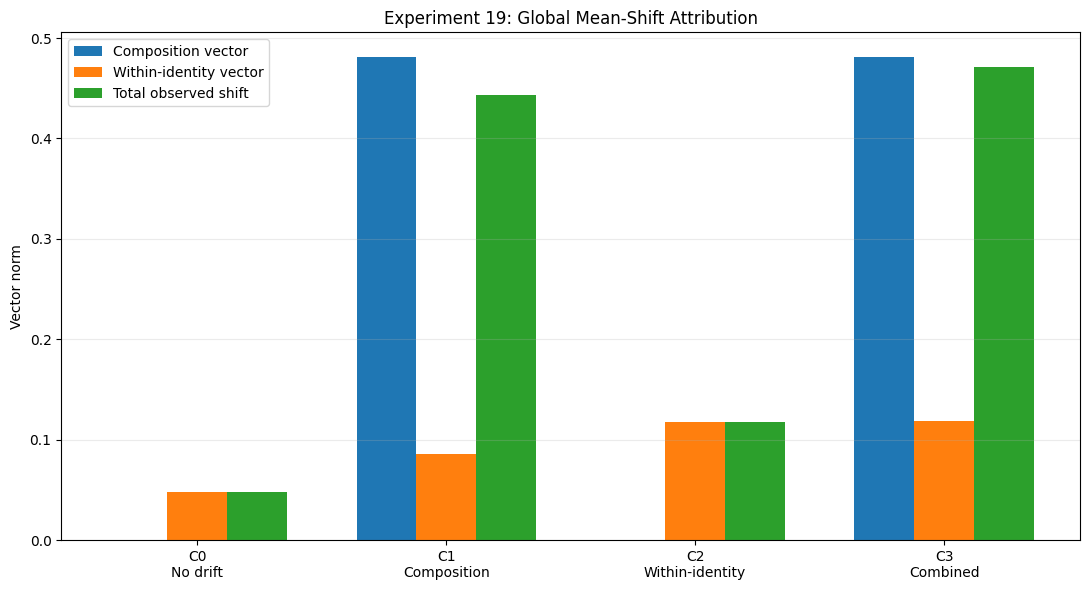

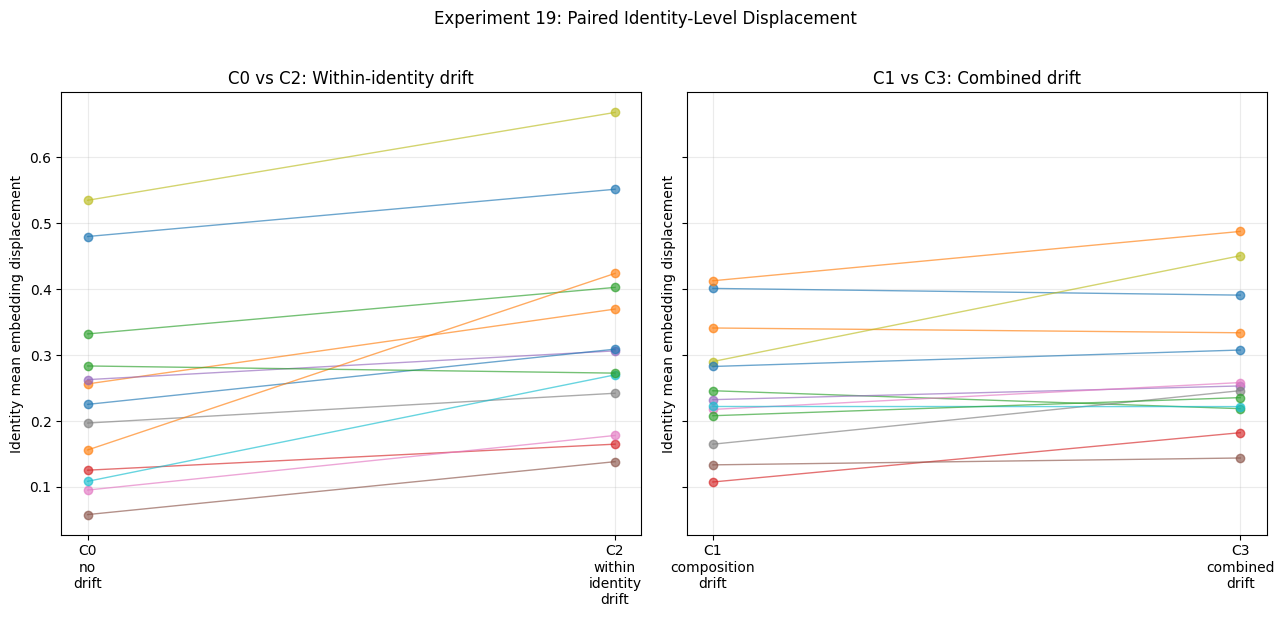

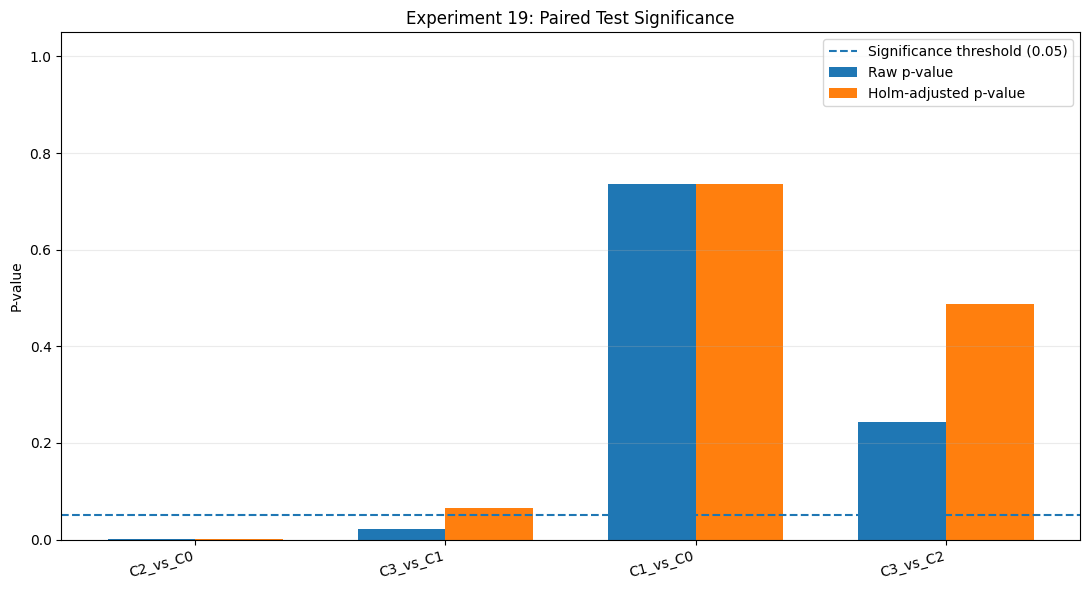


EXPERIMENT 19 — STEP 13
VISUALIZATION OUTPUT

Generated figures:
experiment19_figure1_drift_attribution.png | 113174 bytes
experiment19_figure2_identity_displacement.png | 340740 bytes
experiment19_figure3_statistical_significance.png | 121607 bytes

Figure 1 data:
                scenario  composition_vector_norm  within_identity_vector_norm  total_observed_mean_shift_norm
             C0_no_drift                 0.000000                     0.047761                        0.047761
    C1_composition_drift                 0.481641                     0.085599                        0.443126
C2_within_identity_drift                 0.000000                     0.117821                        0.117821
       C3_combined_drift                 0.481641                     0.118808                        0.471671

Figure 2 identities plotted: 13

Figure 3 statistical comparisons: 4

STEP 13 VISUALIZATIONS COMPLETED.


In [24]:

# EXPERIMENT 19 — STEP 13
# RESEARCH VISUALIZATIONS

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"

RESULTS_DIR = os.path.join(BASE_DIR, "results")
PLOTS_DIR = os.path.join(BASE_DIR, "plots")

os.makedirs(PLOTS_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Load previously saved results
# --------------------------------------------------

ATTRIBUTION_FILE = os.path.join(
    RESULTS_DIR,
    "experiment19_drift_attribution_summary.csv"
)

IDENTITY_FILE = os.path.join(
    RESULTS_DIR,
    "experiment19_drift_attribution_by_identity.csv"
)

STATISTICS_FILE = os.path.join(
    RESULTS_DIR,
    "experiment19_identity_level_statistical_tests.csv"
)

for path in [
    ATTRIBUTION_FILE,
    IDENTITY_FILE,
    STATISTICS_FILE
]:
    assert os.path.isfile(path), f"Missing file: {path}"

attribution = pd.read_csv(ATTRIBUTION_FILE)
identity = pd.read_csv(IDENTITY_FILE)
statistics = pd.read_csv(STATISTICS_FILE)

assert len(attribution) == 4
assert len(identity) == 52
assert len(statistics) == 4

# Consistent scenario order and labels.
scenario_order = [
    "C0_no_drift",
    "C1_composition_drift",
    "C2_within_identity_drift",
    "C3_combined_drift"
]

scenario_labels = [
    "C0\nNo drift",
    "C1\nComposition",
    "C2\nWithin-identity",
    "C3\nCombined"
]

attribution = (
    attribution.set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

# --------------------------------------------------
# 2. Figure 1 — Scenario-level drift attribution
# --------------------------------------------------

metrics = [
    "composition_vector_norm",
    "within_identity_vector_norm",
    "total_observed_mean_shift_norm"
]

metric_labels = [
    "Composition vector",
    "Within-identity vector",
    "Total observed shift"
]

x = np.arange(len(scenario_order))
width = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

for i, (metric, label) in enumerate(
    zip(metrics, metric_labels)
):
    offset = (i - 1) * width

    ax.bar(
        x + offset,
        attribution[metric].to_numpy(),
        width,
        label=label
    )

ax.set_title(
    "Experiment 19: Global Mean-Shift Attribution"
)

ax.set_ylabel("Vector norm")
ax.set_xticks(x)
ax.set_xticklabels(scenario_labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

FIGURE_1 = os.path.join(
    PLOTS_DIR,
    "experiment19_figure1_drift_attribution.png"
)

fig.savefig(FIGURE_1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# 3. Figure 2 — Paired identity-level displacement
# --------------------------------------------------

wide = identity.pivot(
    index="identity",
    columns="scenario",
    values="identity_mean_embedding_displacement"
).sort_index()

assert wide.shape == (13, 4)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    sharey=True
)

paired_comparisons = [
    (
        "C0_no_drift",
        "C2_within_identity_drift",
        "C0 vs C2: Within-identity drift"
    ),
    (
        "C1_composition_drift",
        "C3_combined_drift",
        "C1 vs C3: Combined drift"
    )
]

for ax, (left, right, title) in zip(
    axes, paired_comparisons
):

    for identity_id in wide.index:

        y1 = wide.loc[identity_id, left]
        y2 = wide.loc[identity_id, right]

        ax.plot(
            [0, 1],
            [y1, y2],
            marker="o",
            alpha=0.65,
            linewidth=1
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        left.replace("_", "\n"),
        right.replace("_", "\n")
    ])

    ax.set_title(title)
    ax.set_ylabel("Identity mean embedding displacement")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Experiment 19: Paired Identity-Level Displacement",
    y=1.02
)

fig.tight_layout()

FIGURE_2 = os.path.join(
    PLOTS_DIR,
    "experiment19_figure2_identity_displacement.png"
)

fig.savefig(FIGURE_2, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# 4. Figure 3 — Raw and Holm-adjusted p-values
# --------------------------------------------------

plot_stats = statistics.copy()

labels = plot_stats["comparison"].tolist()
positions = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    positions - width / 2,
    plot_stats["p_value_raw"],
    width,
    label="Raw p-value"
)

ax.bar(
    positions + width / 2,
    plot_stats["p_value_holm"],
    width,
    label="Holm-adjusted p-value"
)

ax.axhline(
    0.05,
    linestyle="--",
    linewidth=1.5,
    label="Significance threshold (0.05)"
)

ax.set_title(
    "Experiment 19: Paired Test Significance"
)

ax.set_ylabel("P-value")
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

FIGURE_3 = os.path.join(
    PLOTS_DIR,
    "experiment19_figure3_statistical_significance.png"
)

fig.savefig(FIGURE_3, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# 5. Verify saved figures
# --------------------------------------------------

figure_files = [
    FIGURE_1,
    FIGURE_2,
    FIGURE_3
]

for path in figure_files:
    assert os.path.isfile(path)
    assert os.path.getsize(path) > 0

print("\n" + "=" * 70)
print("EXPERIMENT 19 — STEP 13")
print("VISUALIZATION OUTPUT")
print("=" * 70)

print("\nGenerated figures:")

for path in figure_files:
    print(
        os.path.basename(path),
        "|",
        os.path.getsize(path),
        "bytes"
    )

print("\nFigure 1 data:")
print(
    attribution[
        ["scenario"] + metrics
    ].to_string(index=False)
)

print("\nFigure 2 identities plotted:", len(wide))
print("\nFigure 3 statistical comparisons:", len(plot_stats))

print("\nSTEP 13 VISUALIZATIONS COMPLETED.")


### Figure 3 — Logarithmic p-value comparison

The original linear-scale chart compresses small p-values and makes the significant result difficult to distinguish. This revised figure uses a logarithmic y-axis to show both small and large p-values clearly.

The dashed horizontal line represents the 0.05 significance threshold. Holm-adjusted p-values remain the basis for determining statistical significance.

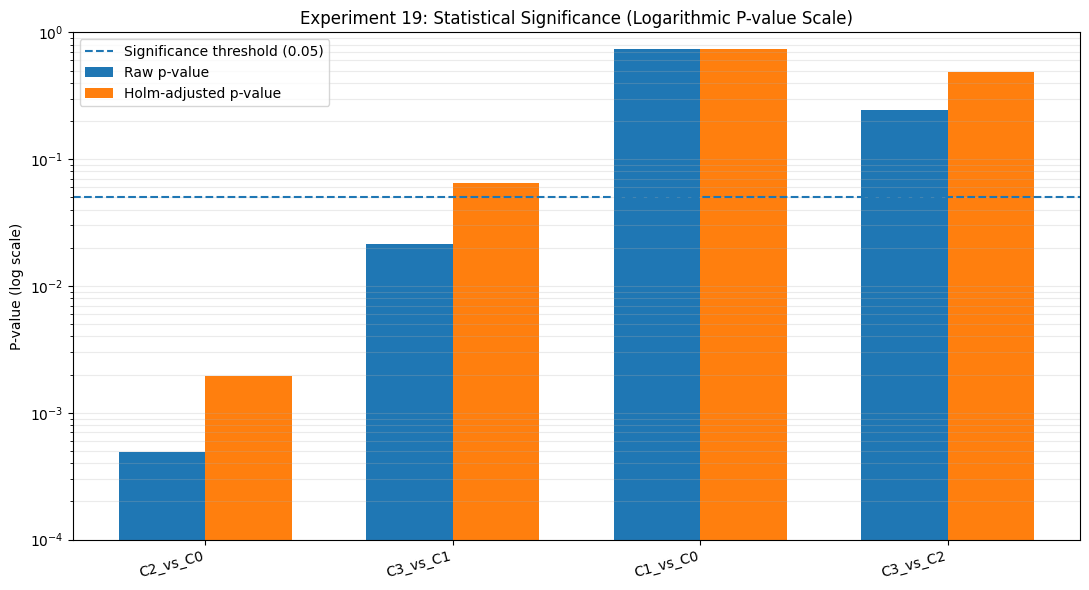

Revised Figure 3 saved:
/content/drive/MyDrive/Experiment_19_Results/plots/experiment19_figure3_statistical_significance.png
File size: 146619 bytes

Holm-adjusted significance:
comparison  p_value_holm  significant_holm_0_05
  C2_vs_C0      0.001953                   True
  C3_vs_C1      0.064453                  False
  C1_vs_C0      0.735352                  False
  C3_vs_C2      0.487793                  False


In [25]:

# STEP 13C — REVISED FIGURE 3
# Logarithmic p-value scale

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"
RESULTS_DIR = os.path.join(BASE_DIR, "results")
PLOTS_DIR = os.path.join(BASE_DIR, "plots")

statistics = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_identity_level_statistical_tests.csv"
    )
)

labels = statistics["comparison"].tolist()
positions = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    positions - width / 2,
    statistics["p_value_raw"],
    width,
    label="Raw p-value"
)

ax.bar(
    positions + width / 2,
    statistics["p_value_holm"],
    width,
    label="Holm-adjusted p-value"
)

ax.axhline(
    0.05,
    linestyle="--",
    linewidth=1.5,
    label="Significance threshold (0.05)"
)

ax.set_yscale("log")
ax.set_ylim(0.0001, 1.0)

ax.set_title(
    "Experiment 19: Statistical Significance "
    "(Logarithmic P-value Scale)"
)

ax.set_ylabel("P-value (log scale)")
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", which="both", alpha=0.25)

fig.tight_layout()

output_path = os.path.join(
    PLOTS_DIR,
    "experiment19_figure3_statistical_significance.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

assert os.path.isfile(output_path)
assert os.path.getsize(output_path) > 0

print("Revised Figure 3 saved:")
print(output_path)
print("File size:", os.path.getsize(output_path), "bytes")
print("\nHolm-adjusted significance:")
print(
    statistics[
        ["comparison", "p_value_holm", "significant_holm_0_05"]
    ].to_string(index=False)
)


## Step 14 — Independent Reproducibility and Artifact Audit

This step independently audits the saved Experiment 19 research artifacts.

The audit verifies:

1. Presence and readability of critical input, configuration, result, and evidence files.
2. Actual packed scenario archive structure, scenario names, embedding dimensions, and labels.
3. Shared baseline consistency across all four scenarios.
4. Reference, evaluation, model-fit, and calibration partition separation.
5. Detector calibration threshold integrity.
6. Statistical result and Holm significance consistency.
7. Integrity of all three final visualization files.
8. SHA-256 checksums for key artifacts.

The controlled-scenario archive stores scenario names and scenario data in packed arrays. The audit reads this structure directly rather than assuming that each scenario is a separate archive field.

This is a verification-only step. Existing experiment outputs will not be regenerated or modified. Two new audit records and a reproducibility manifest will be created.

In [27]:

# EXPERIMENT 19 — STEP 14
# INDEPENDENT REPRODUCIBILITY AUDIT
# CORRECTED VERSION — PACKED SCENARIO ARCHIVE

import os
import json
import hashlib
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"

DIRS = {
    "configuration": os.path.join(BASE_DIR, "configuration"),
    "data": os.path.join(BASE_DIR, "data"),
    "results": os.path.join(BASE_DIR, "results"),
    "plots": os.path.join(BASE_DIR, "plots"),
    "evidence": os.path.join(BASE_DIR, "evidence")
}

audit_results = []

def record_check(name, passed, detail):
    audit_results.append({
        "check": name,
        "passed": bool(passed),
        "detail": str(detail)
    })

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{name}: {detail}"
    )

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()

print("=" * 75)
print("EXPERIMENT 19 — STEP 14")
print("INDEPENDENT REPRODUCIBILITY AUDIT")
print("=" * 75)

# --------------------------------------------------
# 1. REQUIRED ARTIFACT INVENTORY
# --------------------------------------------------

required_files = [
    "configuration/experiment19_environment.json",
    "configuration/experiment19_sampling_protocol_final.json",
    "configuration/experiment19_scenario_generation.json",
    "configuration/experiment19_detector_models_v2.npz",
    "configuration/experiment19_detector_configuration.json",
    "configuration/experiment19_calibrated_thresholds.npz",
    "configuration/experiment19_calibration_thresholds.json",

    "data/experiment19_reference_evaluation_indices.npz",
    "data/experiment19_model_calibration_indices.npz",
    "data/experiment19_controlled_scenarios.npz",

    "results/experiment19_identity_profile.csv",
    "results/experiment19_data_profile.json",
    "results/experiment19_scenario_generation_summary.csv",
    "results/experiment19_scenario_validation.csv",
    "results/experiment19_no_drift_window_scores.csv",
    "results/experiment19_no_drift_control_summary.csv",
    "results/experiment19_drift_window_scores.csv",
    "results/experiment19_drift_detection_summary.csv",
    "results/experiment19_drift_attribution_summary.csv",
    "results/experiment19_drift_attribution_by_identity.csv",
    "results/experiment19_identity_level_statistical_tests.csv",
    "results/experiment19_identity_level_paired_differences.csv",

    "plots/experiment19_figure1_drift_attribution.png",
    "plots/experiment19_figure2_identity_displacement.png",
    "plots/experiment19_figure3_statistical_significance.png",

    "evidence/experiment19_scenario_validation.json",
    "evidence/experiment19_no_drift_control.json",
    "evidence/experiment19_drift_detection.json",
    "evidence/experiment19_drift_attribution.json",
    "evidence/experiment19_identity_level_statistics.json"
]

missing_files = []

print("\n1. ARTIFACT INVENTORY")

for relative_path in required_files:

    full_path = os.path.join(BASE_DIR, relative_path)

    exists = os.path.isfile(full_path)
    nonempty = exists and os.path.getsize(full_path) > 0

    record_check(
        f"Artifact: {relative_path}",
        exists and nonempty,
        f"exists={exists}, nonempty={nonempty}"
    )

    if not nonempty:
        missing_files.append(relative_path)

# --------------------------------------------------
# 2. LOAD CORE ARCHIVES
# --------------------------------------------------

print("\n2. CORE ARCHIVE LOADING")

scenario_path = os.path.join(
    DIRS["data"],
    "experiment19_controlled_scenarios.npz"
)

split_path = os.path.join(
    DIRS["data"],
    "experiment19_reference_evaluation_indices.npz"
)

model_split_path = os.path.join(
    DIRS["data"],
    "experiment19_model_calibration_indices.npz"
)

threshold_path = os.path.join(
    DIRS["configuration"],
    "experiment19_calibrated_thresholds.npz"
)

archives_loaded = True

try:
    scenarios = np.load(
        scenario_path,
        allow_pickle=False
    )

    splits = np.load(
        split_path,
        allow_pickle=False
    )

    model_splits = np.load(
        model_split_path,
        allow_pickle=False
    )

    thresholds = np.load(
        threshold_path,
        allow_pickle=False
    )

except Exception as error:
    archives_loaded = False
    print("Archive loading error:", repr(error))

record_check(
    "Core NPZ archives readable",
    archives_loaded,
    f"loaded={archives_loaded}"
)

# --------------------------------------------------
# 3. PACKED SCENARIO STRUCTURE AUDIT
# --------------------------------------------------

scenario_structure_valid = False
scenario_names = []

if archives_loaded:

    required_scenario_fields = [
        "scenario_names",
        "scenario_embeddings",
        "scenario_labels",
        "scenario_source_indices",
        "baseline_observations",
        "post_change_observations",
        "window_size",
        "random_seed"
    ]

    fields_present = all(
        key in scenarios.files
        for key in required_scenario_fields
    )

    record_check(
        "Packed scenario archive fields",
        fields_present,
        f"fields present={fields_present}"
    )

    if fields_present:

        scenario_names = [
            str(name)
            for name in scenarios["scenario_names"].tolist()
        ]

        embeddings = scenarios["scenario_embeddings"]
        labels = scenarios["scenario_labels"]
        source_indices = scenarios["scenario_source_indices"]

        expected_names = [
            "C0_no_drift",
            "C1_composition_drift",
            "C2_within_identity_drift",
            "C3_combined_drift"
        ]

        names_valid = scenario_names == expected_names

        record_check(
            "Four expected scenario names",
            names_valid,
            f"names={scenario_names}"
        )

        print("\nScenario embeddings shape:", embeddings.shape)
        print("Scenario labels shape:", labels.shape)
        print("Source indices shape:", source_indices.shape)

        structure_valid = (
            embeddings.ndim == 3
            and embeddings.shape[0] == 4
            and embeddings.shape[1:] == (440, 512)
            and labels.shape == (4, 440)
            and source_indices.shape == (4, 440)
        )

        record_check(
            "Packed scenario dimensions",
            structure_valid,
            f"embeddings={embeddings.shape}, "
            f"labels={labels.shape}, "
            f"source_indices={source_indices.shape}"
        )

        finite_embeddings = np.isfinite(embeddings).all()

        record_check(
            "Scenario embeddings finite",
            finite_embeddings,
            f"all finite={finite_embeddings}"
        )

        # Check baseline consistency across all scenarios.
        baseline_identical = False

        if structure_valid:

            baseline_arrays = [
                embeddings[i, :220]
                for i in range(4)
            ]

            baseline_identical = all(
                np.array_equal(
                    baseline_arrays[0],
                    baseline_arrays[i]
                )
                for i in range(1, 4)
            )

        record_check(
            "Shared baseline consistency",
            baseline_identical,
            f"identical across scenarios={baseline_identical}"
        )

        # Check baseline and post-change allocation.
        baseline_count = int(
            np.asarray(
                scenarios["baseline_observations"]
            ).item()
        )

        post_count = int(
            np.asarray(
                scenarios["post_change_observations"]
            ).item()
        )

        allocation_valid = (
            baseline_count == 220
            and post_count == 220
        )

        record_check(
            "Scenario observation allocation",
            allocation_valid,
            f"baseline={baseline_count}, post={post_count}"
        )

        window_size = int(
            np.asarray(
                scenarios["window_size"]
            ).item()
        )

        record_check(
            "Scenario window size",
            window_size == 20,
            f"window_size={window_size}"
        )

        scenario_structure_valid = (
            fields_present
            and names_valid
            and structure_valid
            and finite_embeddings
            and baseline_identical
            and allocation_valid
            and window_size == 20
        )

# --------------------------------------------------
# 4. REFERENCE / EVALUATION PARTITION AUDIT
# --------------------------------------------------

print("\n4. REFERENCE AND EVALUATION PARTITIONS")

if archives_loaded:

    required_split_fields = [
        "reference_indices",
        "evaluation_indices",
        "reference_labels",
        "evaluation_labels"
    ]

    split_fields_present = all(
        key in splits.files
        for key in required_split_fields
    )

    record_check(
        "Reference/evaluation split fields",
        split_fields_present,
        f"fields present={split_fields_present}"
    )

    if split_fields_present:

        reference_indices = splits["reference_indices"]
        evaluation_indices = splits["evaluation_indices"]

        partition_disjoint = (
            len(
                np.intersect1d(
                    reference_indices,
                    evaluation_indices
                )
            ) == 0
        )

        record_check(
            "Reference/evaluation disjointness",
            partition_disjoint,
            f"reference={len(reference_indices)}, "
            f"evaluation={len(evaluation_indices)}"
        )

        record_check(
            "Reference/evaluation allocation",
            len(reference_indices) == 442
            and len(evaluation_indices) == 447,
            f"reference={len(reference_indices)}, "
            f"evaluation={len(evaluation_indices)}"
        )

# --------------------------------------------------
# 5. MODEL-FIT / CALIBRATION PARTITION AUDIT
# --------------------------------------------------

print("\n5. MODEL AND CALIBRATION PARTITIONS")

if archives_loaded:

    required_model_fields = [
        "model_fit_indices",
        "model_fit_labels",
        "calibration_indices",
        "calibration_labels"
    ]

    model_fields_present = all(
        key in model_splits.files
        for key in required_model_fields
    )

    record_check(
        "Model/calibration split fields",
        model_fields_present,
        f"fields present={model_fields_present}"
    )

    if model_fields_present:

        fit_indices = model_splits["model_fit_indices"]
        calibration_indices = model_splits["calibration_indices"]

        fit_calibration_disjoint = (
            len(
                np.intersect1d(
                    fit_indices,
                    calibration_indices
                )
            ) == 0
        )

        record_check(
            "Model-fit/calibration disjointness",
            fit_calibration_disjoint,
            f"fit={len(fit_indices)}, "
            f"calibration={len(calibration_indices)}"
        )

        record_check(
            "Model-fit/calibration allocation",
            len(fit_indices) == 261
            and len(calibration_indices) == 181,
            f"fit={len(fit_indices)}, "
            f"calibration={len(calibration_indices)}"
        )

# --------------------------------------------------
# 6. CALIBRATION THRESHOLD AUDIT
# --------------------------------------------------

print("\n6. CALIBRATION THRESHOLD AUDIT")

if archives_loaded:

    threshold_keys = [
        "global_euclidean_thresholds",
        "global_mahalanobis_thresholds",
        "identity_conditioned_thresholds"
    ]

    threshold_fields_present = all(
        key in thresholds.files
        for key in threshold_keys
    )

    record_check(
        "Three detector threshold arrays",
        threshold_fields_present,
        f"available={thresholds.files}"
    )

    if threshold_fields_present:

        for key in threshold_keys:

            values = thresholds[key]

            record_check(
                f"Finite thresholds: {key}",
                np.isfinite(values).all(),
                f"shape={values.shape}"
            )

# --------------------------------------------------
# 7. STATISTICAL RESULT AUDIT
# --------------------------------------------------

print("\n7. STATISTICAL RESULT AUDIT")

statistics_path = os.path.join(
    DIRS["results"],
    "experiment19_identity_level_statistical_tests.csv"
)

statistics = pd.read_csv(statistics_path)

required_stat_columns = [
    "comparison",
    "p_value_raw",
    "p_value_holm",
    "significant_holm_0_05"
]

stat_columns_present = all(
    column in statistics.columns
    for column in required_stat_columns
)

record_check(
    "Statistical result columns",
    stat_columns_present,
    f"columns present={stat_columns_present}"
)

if stat_columns_present:

    p_values_valid = (
        statistics["p_value_raw"].between(0, 1).all()
        and statistics["p_value_holm"].between(0, 1).all()
    )

    record_check(
        "Statistical p-value ranges",
        p_values_valid,
        "All p-values are between 0 and 1"
    )

    expected_significance = (
        statistics["p_value_holm"] < 0.05
    )

    stored_significance = (
        statistics["significant_holm_0_05"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False})
    )

    significance_consistent = (
        stored_significance.notna().all()
        and np.array_equal(
            expected_significance.to_numpy(),
            stored_significance.to_numpy()
        )
    )

    record_check(
        "Holm significance consistency",
        significance_consistent,
        f"significant comparisons="
        f"{statistics.loc[expected_significance, 'comparison'].tolist()}"
    )

# --------------------------------------------------
# 8. VISUALIZATION INTEGRITY
# --------------------------------------------------

print("\n8. VISUALIZATION INTEGRITY")

plot_files = [
    "experiment19_figure1_drift_attribution.png",
    "experiment19_figure2_identity_displacement.png",
    "experiment19_figure3_statistical_significance.png"
]

for filename in plot_files:

    path = os.path.join(
        DIRS["plots"],
        filename
    )

    valid_png = False

    if os.path.isfile(path):

        with open(path, "rb") as file:
            valid_png = (
                file.read(8)
                == b"\x89PNG\r\n\x1a\n"
            )

    record_check(
        f"PNG integrity: {filename}",
        valid_png,
        f"valid PNG signature={valid_png}"
    )

# --------------------------------------------------
# 9. SHA-256 REPRODUCIBILITY MANIFEST
# --------------------------------------------------

print("\n9. SHA-256 MANIFEST")

manifest_paths = [
    scenario_path,
    split_path,
    model_split_path,
    threshold_path,
    statistics_path
] + [
    os.path.join(DIRS["plots"], filename)
    for filename in plot_files
]

manifest = []

for path in manifest_paths:

    if os.path.isfile(path):

        manifest.append({
            "file": os.path.relpath(path, BASE_DIR),
            "size_bytes": os.path.getsize(path),
            "sha256": sha256_file(path)
        })

manifest_path = os.path.join(
    DIRS["evidence"],
    "experiment19_reproducibility_manifest.json"
)

with open(manifest_path, "w") as file:
    json.dump(manifest, file, indent=2)

record_check(
    "SHA-256 manifest created",
    os.path.isfile(manifest_path)
    and len(manifest) == len(manifest_paths),
    f"manifest entries={len(manifest)}"
)

# --------------------------------------------------
# 10. FINAL AUDIT SUMMARY
# --------------------------------------------------

print("\n10. FINAL AUDIT SUMMARY")

audit_df = pd.DataFrame(audit_results)

audit_csv_path = os.path.join(
    DIRS["results"],
    "experiment19_reproducibility_audit.csv"
)

audit_json_path = os.path.join(
    DIRS["evidence"],
    "experiment19_reproducibility_audit.json"
)

audit_df.to_csv(
    audit_csv_path,
    index=False
)

failed_checks = audit_df[
    ~audit_df["passed"]
]["check"].tolist()

summary = {
    "total_checks": int(len(audit_df)),
    "passed_checks": int(audit_df["passed"].sum()),
    "failed_checks_count": int(
        (~audit_df["passed"]).sum()
    ),
    "failed_check_names": failed_checks,
    "missing_artifacts": missing_files,
    "scenario_archive_structure_valid": bool(
        scenario_structure_valid
    ),
    "audit_status": (
        "PASS"
        if audit_df["passed"].all()
        else "REVIEW_REQUIRED"
    ),
    "manifest_file": os.path.relpath(
        manifest_path,
        BASE_DIR
    )
}

with open(audit_json_path, "w") as file:
    json.dump(summary, file, indent=2)

print("\n" + "=" * 75)
print("FINAL REPRODUCIBILITY AUDIT SUMMARY")
print("=" * 75)

print(json.dumps(summary, indent=2))

print("\nAudit CSV:", audit_csv_path)
print("Audit JSON:", audit_json_path)
print("Manifest:", manifest_path)

print("\nSTEP 14 AUDIT EXECUTION COMPLETED.")


EXPERIMENT 19 — STEP 14
INDEPENDENT REPRODUCIBILITY AUDIT

1. ARTIFACT INVENTORY
[PASS] Artifact: configuration/experiment19_environment.json: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_sampling_protocol_final.json: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_scenario_generation.json: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_detector_models_v2.npz: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_detector_configuration.json: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_calibrated_thresholds.npz: exists=True, nonempty=True
[PASS] Artifact: configuration/experiment19_calibration_thresholds.json: exists=True, nonempty=True
[PASS] Artifact: data/experiment19_reference_evaluation_indices.npz: exists=True, nonempty=True
[PASS] Artifact: data/experiment19_model_calibration_indices.npz: exists=True, nonempty=True
[PASS] Artifact: data/experiment19_controlled_scen

## Step 15 — Research Findings and Limitations

This step consolidates the empirical findings from Experiment 19.

The analysis will cover:

1. Global detection of identity-composition drift.
2. Detection of within-identity embedding displacement.
3. Combined drift behaviour.
4. Mathematical drift-mechanism attribution.
5. Identity-level paired statistical findings.
6. False-alarm observations under the no-drift control.
7. Sampling, calibration, and generalisation limitations.

The conclusions will be restricted to the controlled LFW-derived embedding experiment. They will not be presented as evidence of real-world biometric recognition accuracy, operational fairness, causal mechanism isolation, or deployment readiness.

No experimental data will be regenerated or modified.

In [28]:

# EXPERIMENT 19 — STEP 15
# FINDINGS AND LIMITATIONS REPORT

import os
import json
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"

RESULTS_DIR = os.path.join(BASE_DIR, "results")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")

# Load saved results
attribution = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_drift_attribution_summary.csv"
    )
)

statistics = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_identity_level_statistical_tests.csv"
    )
)

detection = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_drift_detection_summary.csv"
    )
)

control = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_no_drift_control_summary.csv"
    )
)

audit = json.load(
    open(
        os.path.join(
            EVIDENCE_DIR,
            "experiment19_reproducibility_audit.json"
        )
    )
)

# --------------------------------------------------
# Findings
# --------------------------------------------------

findings = {
    "experiment": 19,

    "title": (
        "Disentangling Identity-Composition Drift from "
        "Within-Identity Embedding Drift in Biometric "
        "Representation Systems"
    ),

    "research_findings": [
        {
            "finding": "Global composition drift",
            "evidence": (
                "Global Euclidean and Mahalanobis detectors "
                "detected all 11 post-change windows in C1 "
                "and C3 at the 5% threshold."
            ),
            "interpretation": (
                "The global embedding distribution was "
                "sensitive to the constructed identity-composition "
                "changes."
            )
        },
        {
            "finding": "Within-identity drift",
            "evidence": (
                "C2 produced greater identity-level displacement "
                "than C0, with a mean paired difference of "
                "0.091008 and Holm-adjusted p-value of 0.001953."
            ),
            "interpretation": (
                "The low-illumination condition produced measurable "
                "within-identity embedding displacement."
            )
        },
        {
            "finding": "Combined drift",
            "evidence": (
                "C3 versus C1 had a positive mean paired difference "
                "of 0.036232, but its Holm-adjusted p-value was "
                "0.064453."
            ),
            "interpretation": (
                "The additional within-identity effect under the "
                "combined condition was not statistically significant "
                "after Holm correction."
            )
        },
        {
            "finding": "Mathematical attribution",
            "evidence": (
                "The vector decomposition reconstructed the total "
                "mean shift with maximum numerical error "
                "8.85e-17."
            ),
            "interpretation": (
                "The decomposition is numerically consistent, "
                "but its estimated components include sampling noise."
            )
        }
    ],

    "limitations": [
        "The experiment uses a filtered LFW-derived subset containing 13 identities.",
        "Identity 14 accounts for approximately 56.69% of the original paired cohort.",
        "Bootstrap sampling with replacement means repeated draws are not independent images.",
        "The evaluation contains only 22 windows per scenario.",
        "Calibration thresholds are based on 181 calibration observations and bootstrap windows.",
        "Identity-conditioned monitoring requires identity labels.",
        "The within-identity drift scenario uses low-illumination embedding variants.",
        "The post-change samples are independently resampled rather than strictly paired image observations.",
        "The statistical analysis uses only 13 identity-level paired observations.",
        "The results do not establish real-world biometric recognition accuracy.",
        "The results do not establish operational fairness or deployment readiness.",
        "The experiment does not establish causal isolation of drift mechanisms."
    ],

    "reproducibility_audit": {
        "status": audit["audit_status"],
        "total_checks": audit["total_checks"],
        "passed_checks": audit["passed_checks"],
        "failed_checks": audit["failed_checks_count"]
    }
}

# --------------------------------------------------
# Save report
# --------------------------------------------------

output_path = os.path.join(
    EVIDENCE_DIR,
    "experiment19_findings_and_limitations.json"
)

with open(output_path, "w") as file:
    json.dump(findings, file, indent=2)

# --------------------------------------------------
# Print review summary
# --------------------------------------------------

print("=" * 75)
print("EXPERIMENT 19 — STEP 15")
print("FINDINGS AND LIMITATIONS")
print("=" * 75)

print("\nRESEARCH FINDINGS")

for item in findings["research_findings"]:
    print("\n", item["finding"])
    print("Evidence:", item["evidence"])
    print("Interpretation:", item["interpretation"])

print("\nLIMITATIONS")

for number, limitation in enumerate(
    findings["limitations"], start=1
):
    print(f"{number}. {limitation}")

print("\nREPRODUCIBILITY AUDIT")
print(json.dumps(
    findings["reproducibility_audit"],
    indent=2
))

print("\nSaved:", output_path)
print("\nSTEP 15 FINDINGS REPORT GENERATED.")


EXPERIMENT 19 — STEP 15
FINDINGS AND LIMITATIONS

RESEARCH FINDINGS

 Global composition drift
Evidence: Global Euclidean and Mahalanobis detectors detected all 11 post-change windows in C1 and C3 at the 5% threshold.
Interpretation: The global embedding distribution was sensitive to the constructed identity-composition changes.

 Within-identity drift
Evidence: C2 produced greater identity-level displacement than C0, with a mean paired difference of 0.091008 and Holm-adjusted p-value of 0.001953.
Interpretation: The low-illumination condition produced measurable within-identity embedding displacement.

 Combined drift
Evidence: C3 versus C1 had a positive mean paired difference of 0.036232, but its Holm-adjusted p-value was 0.064453.
Interpretation: The additional within-identity effect under the combined condition was not statistically significant after Holm correction.

 Mathematical attribution
Evidence: The vector decomposition reconstructed the total mean shift with maximum numer

## Step 16 — Research Evidence Generation

This step consolidates the saved Experiment 19 outputs into a structured evidence package.

The package contains:

- A machine-readable evidence index.
- A human-readable research evidence report.
- References to the saved figures, statistical results, scenario validation, and reproducibility audit.
- Explicit methodological limitations and interpretation boundaries.

The evidence package is generated exclusively from existing Experiment 19 artifacts. No experiments, detector evaluations, or statistical tests are rerun.

In [29]:

# EXPERIMENT 19 — STEP 16
# CONSOLIDATED RESEARCH EVIDENCE GENERATION

import os
import json
import hashlib
import pandas as pd
from datetime import datetime, timezone

BASE_DIR = "/content/drive/MyDrive/Experiment_19_Results"

RESULTS_DIR = os.path.join(BASE_DIR, "results")
EVIDENCE_DIR = os.path.join(BASE_DIR, "evidence")
PLOTS_DIR = os.path.join(BASE_DIR, "plots")
DATA_DIR = os.path.join(BASE_DIR, "data")
CONFIG_DIR = os.path.join(BASE_DIR, "configuration")

os.makedirs(EVIDENCE_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Load existing evidence
# --------------------------------------------------

def load_json(path):
    with open(path, "r") as file:
        return json.load(file)

attribution = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_drift_attribution_summary.csv"
    )
)

statistics = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_identity_level_statistical_tests.csv"
    )
)

detection = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_drift_detection_summary.csv"
    )
)

control = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "experiment19_no_drift_control_summary.csv"
    )
)

validation = load_json(
    os.path.join(
        EVIDENCE_DIR,
        "experiment19_scenario_validation.json"
    )
)

findings = load_json(
    os.path.join(
        EVIDENCE_DIR,
        "experiment19_findings_and_limitations.json"
    )
)

reproducibility = load_json(
    os.path.join(
        EVIDENCE_DIR,
        "experiment19_reproducibility_audit.json"
    )
)

# --------------------------------------------------
# 2. Define evidence inventory
# --------------------------------------------------

evidence_files = [
    "configuration/experiment19_environment.json",
    "configuration/experiment19_sampling_protocol_final.json",
    "configuration/experiment19_scenario_generation.json",
    "configuration/experiment19_detector_configuration.json",
    "configuration/experiment19_calibration_thresholds.json",

    "data/experiment19_controlled_scenarios.npz",
    "data/experiment19_reference_evaluation_indices.npz",
    "data/experiment19_model_calibration_indices.npz",

    "results/experiment19_scenario_validation.csv",
    "results/experiment19_no_drift_control_summary.csv",
    "results/experiment19_drift_detection_summary.csv",
    "results/experiment19_drift_attribution_summary.csv",
    "results/experiment19_drift_attribution_by_identity.csv",
    "results/experiment19_identity_level_statistical_tests.csv",
    "results/experiment19_identity_level_paired_differences.csv",
    "results/experiment19_reproducibility_audit.csv",

    "evidence/experiment19_scenario_validation.json",
    "evidence/experiment19_no_drift_control.json",
    "evidence/experiment19_drift_detection.json",
    "evidence/experiment19_drift_attribution.json",
    "evidence/experiment19_identity_level_statistics.json",
    "evidence/experiment19_findings_and_limitations.json",
    "evidence/experiment19_reproducibility_audit.json",
    "evidence/experiment19_reproducibility_manifest.json",

    "plots/experiment19_figure1_drift_attribution.png",
    "plots/experiment19_figure2_identity_displacement.png",
    "plots/experiment19_figure3_statistical_significance.png"
]

inventory = []

for relative_path in evidence_files:

    full_path = os.path.join(BASE_DIR, relative_path)

    exists = os.path.isfile(full_path)

    inventory.append({
        "path": relative_path,
        "exists": exists,
        "size_bytes": (
            os.path.getsize(full_path)
            if exists else None
        )
    })

missing_evidence = [
    item["path"]
    for item in inventory
    if not item["exists"]
]

# --------------------------------------------------
# 3. Build machine-readable evidence index
# --------------------------------------------------

evidence_index = {
    "experiment_id": 19,

    "title": (
        "Disentangling Identity-Composition Drift from "
        "Within-Identity Embedding Drift in Biometric "
        "Representation Systems"
    ),

    "generated_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "research_questions": [
        "How do changes in identity composition affect global embedding distributions?",
        "Can within-identity embedding distribution changes be detected independently of identity-composition changes?",
        "How effectively can global and identity-conditioned monitoring distinguish mechanisms?",
        "How do detection performance and false alarms change when both mechanisms occur simultaneously?"
    ],

    "scenario_design": [
        {
            "scenario": "C0_no_drift",
            "description": "Stable identity composition and conditional distributions."
        },
        {
            "scenario": "C1_composition_drift",
            "description": "Changed identity proportions with original embeddings."
        },
        {
            "scenario": "C2_within_identity_drift",
            "description": "Stable identity proportions with low-illumination embedding variants."
        },
        {
            "scenario": "C3_combined_drift",
            "description": "Changed identity proportions and low-illumination embedding variants."
        }
    ],

    "key_findings": findings["research_findings"],

    "limitations": findings["limitations"],

    "reproducibility": reproducibility,

    "evidence_inventory": inventory,

    "missing_evidence_files": missing_evidence
}

index_path = os.path.join(
    EVIDENCE_DIR,
    "experiment19_consolidated_evidence_index.json"
)

with open(index_path, "w") as file:
    json.dump(evidence_index, file, indent=2)

# --------------------------------------------------
# 4. Build human-readable research report
# --------------------------------------------------

report = []

report.append("# Experiment 19 — Consolidated Research Evidence")
report.append("")

report.append("## Research Title")
report.append("")
report.append(evidence_index["title"])
report.append("")

report.append("## Research Questions")
report.append("")

for i, question in enumerate(
    evidence_index["research_questions"], 1
):
    report.append(f"{i}. {question}")

report.append("")
report.append("## Experimental Scenarios")
report.append("")

for scenario in evidence_index["scenario_design"]:
    report.append(
        f"### {scenario['scenario']}"
    )
    report.append(scenario["description"])
    report.append("")

report.append("## Main Research Findings")
report.append("")

for finding in findings["research_findings"]:

    report.append(f"### {finding['finding']}")
    report.append("")
    report.append(f"**Evidence:** {finding['evidence']}")
    report.append("")
    report.append(
        f"**Interpretation:** {finding['interpretation']}"
    )
    report.append("")

report.append("## Identity-Level Statistical Results")
report.append("")

report.append(
    statistics[
        [
            "comparison",
            "mean_paired_difference",
            "p_value_raw",
            "p_value_holm",
            "cohens_dz",
            "significant_holm_0_05"
        ]
    ].to_markdown(index=False)
)

report.append("")
report.append("## Drift Attribution Results")
report.append("")

report.append(
    attribution.to_markdown(index=False)
)

report.append("")
report.append("## Detector Evaluation")
report.append("")

report.append(
    detection.to_markdown(index=False)
)

report.append("")
report.append("## No-Drift Control")
report.append("")

report.append(
    control.to_markdown(index=False)
)

report.append("")
report.append("## Methodological Limitations")
report.append("")

for limitation in findings["limitations"]:
    report.append(f"- {limitation}")

report.append("")
report.append("## Reproducibility Audit")
report.append("")

report.append(
    f"- Status: {reproducibility['audit_status']}"
)

report.append(
    f"- Checks passed: {reproducibility['passed_checks']}/"
    f"{reproducibility['total_checks']}"
)

report.append(
    f"- Failed checks: {reproducibility['failed_checks_count']}"
)

report.append("")
report.append("## Generated Figures")
report.append("")

for filename in [
    "experiment19_figure1_drift_attribution.png",
    "experiment19_figure2_identity_displacement.png",
    "experiment19_figure3_statistical_significance.png"
]:
    report.append(f"- `plots/{filename}`")

report.append("")
report.append("## Interpretation Boundary")
report.append("")

report.append(
    "These findings are limited to the controlled LFW-derived "
    "embedding experiment. Identity labels are used for scenario "
    "construction and identity-conditioned analysis. The results "
    "do not demonstrate label-free operational monitoring, "
    "real-world biometric recognition accuracy, fairness, "
    "causal mechanism isolation, or deployment readiness."
)

report.append("")
report.append(
    "This report consolidates previously saved results. "
    "No experiment or statistical test was rerun."
)

report_text = "\n".join(report)

report_path = os.path.join(
    EVIDENCE_DIR,
    "experiment19_consolidated_research_evidence.md"
)

with open(report_path, "w") as file:
    file.write(report_text)

# --------------------------------------------------
# 5. Verify generated evidence
# --------------------------------------------------

assert os.path.isfile(index_path)
assert os.path.getsize(index_path) > 0

assert os.path.isfile(report_path)
assert os.path.getsize(report_path) > 0

print("=" * 75)
print("EXPERIMENT 19 — STEP 16")
print("CONSOLIDATED RESEARCH EVIDENCE")
print("=" * 75)

print("\nEvidence inventory:")
print("Total files:", len(inventory))
print("Missing files:", len(missing_evidence))

for item in inventory:
    print(
        f"[{'PASS' if item['exists'] else 'MISSING'}] "
        f"{item['path']}"
    )

print("\nGenerated outputs:")
print(index_path)
print(report_path)

print("\nReport size:", os.path.getsize(report_path), "bytes")
print("Index size:", os.path.getsize(index_path), "bytes")

print("\nSTEP 16 EVIDENCE GENERATION COMPLETED.")


EXPERIMENT 19 — STEP 16
CONSOLIDATED RESEARCH EVIDENCE

Evidence inventory:
Total files: 27
Missing files: 0
[PASS] configuration/experiment19_environment.json
[PASS] configuration/experiment19_sampling_protocol_final.json
[PASS] configuration/experiment19_scenario_generation.json
[PASS] configuration/experiment19_detector_configuration.json
[PASS] configuration/experiment19_calibration_thresholds.json
[PASS] data/experiment19_controlled_scenarios.npz
[PASS] data/experiment19_reference_evaluation_indices.npz
[PASS] data/experiment19_model_calibration_indices.npz
[PASS] results/experiment19_scenario_validation.csv
[PASS] results/experiment19_no_drift_control_summary.csv
[PASS] results/experiment19_drift_detection_summary.csv
[PASS] results/experiment19_drift_attribution_summary.csv
[PASS] results/experiment19_drift_attribution_by_identity.csv
[PASS] results/experiment19_identity_level_statistical_tests.csv
[PASS] results/experiment19_identity_level_paired_differences.csv
[PASS] results/

## Step 17 — Final Research Package Creation

This step creates a consolidated ZIP archive containing the complete Experiment 19 research artifacts.

The package will preserve the existing folder structure:

- configuration/
- data/
- results/
- plots/
- evidence/

The archive will include the experiment outputs, statistical analysis, figures, reproducibility records, and consolidated research report.

After creation, the archive will be tested for integrity and its contents will be independently inventoried.

No existing experimental files will be modified.

In [30]:

# EXPERIMENT 19 — STEP 17
# FINAL RESEARCH PACKAGE CREATION AND VALIDATION

import os
import json
import zipfile
import hashlib
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Experiment_19_Results"
)

PACKAGE_NAME = "Experiment_19_Final_Research_Package.zip"

PACKAGE_PATH = BASE_DIR / PACKAGE_NAME

REQUIRED_DIRS = [
    "configuration",
    "data",
    "results",
    "plots",
    "evidence"
]

print("=" * 75)
print("EXPERIMENT 19 — STEP 17")
print("FINAL RESEARCH PACKAGE")
print("=" * 75)

# --------------------------------------------------
# 1. Verify required directories
# --------------------------------------------------

for directory in REQUIRED_DIRS:

    directory_path = BASE_DIR / directory

    assert directory_path.is_dir(), (
        f"Missing directory: {directory}"
    )

    print("[PASS] Directory:", directory)

# --------------------------------------------------
# 2. Collect files
# --------------------------------------------------

files_to_package = []

for directory in REQUIRED_DIRS:

    directory_path = BASE_DIR / directory

    for path in directory_path.rglob("*"):

        if path.is_file():
            files_to_package.append(path)

files_to_package = sorted(files_to_package)

assert len(files_to_package) > 0

print("\nFiles collected:", len(files_to_package))

# --------------------------------------------------
# 3. Create ZIP archive
# --------------------------------------------------

if PACKAGE_PATH.exists():
    PACKAGE_PATH.unlink()

with zipfile.ZipFile(
    PACKAGE_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:

    for file_path in files_to_package:

        relative_path = file_path.relative_to(BASE_DIR)

        archive.write(
            file_path,
            arcname=str(relative_path)
        )

print("\nZIP archive created:")
print(PACKAGE_PATH)

# --------------------------------------------------
# 4. Verify ZIP integrity
# --------------------------------------------------

with zipfile.ZipFile(PACKAGE_PATH, "r") as archive:

    bad_file = archive.testzip()

    zip_contents = archive.namelist()

    zip_integrity = bad_file is None

print("\nZIP integrity:", zip_integrity)

assert zip_integrity, (
    f"ZIP integrity failure: {bad_file}"
)

# --------------------------------------------------
# 5. Verify expected file inventory
# --------------------------------------------------

expected_paths = {
    str(path.relative_to(BASE_DIR))
    for path in files_to_package
}

archived_paths = set(zip_contents)

missing_from_zip = expected_paths - archived_paths
unexpected_in_zip = archived_paths - expected_paths

print("\nExpected files:", len(expected_paths))
print("Archived files:", len(archived_paths))
print("Missing from ZIP:", len(missing_from_zip))
print("Unexpected files:", len(unexpected_in_zip))

assert len(missing_from_zip) == 0
assert len(unexpected_in_zip) == 0

# --------------------------------------------------
# 6. Calculate ZIP SHA-256
# --------------------------------------------------

digest = hashlib.sha256()

with open(PACKAGE_PATH, "rb") as file:

    for block in iter(
        lambda: file.read(1024 * 1024),
        b""
    ):
        digest.update(block)

zip_sha256 = digest.hexdigest()

# --------------------------------------------------
# 7. Save package metadata
# --------------------------------------------------

package_metadata = {
    "experiment": 19,
    "package_name": PACKAGE_NAME,
    "package_size_bytes": PACKAGE_PATH.stat().st_size,
    "file_count": len(archived_paths),
    "zip_integrity": zip_integrity,
    "missing_files": list(missing_from_zip),
    "unexpected_files": list(unexpected_in_zip),
    "sha256": zip_sha256,
    "archive_structure": REQUIRED_DIRS
}

metadata_path = (
    BASE_DIR
    / "evidence"
    / "experiment19_final_package_metadata.json"
)

with open(metadata_path, "w") as file:
    json.dump(package_metadata, file, indent=2)

# --------------------------------------------------
# 8. Final verification
# --------------------------------------------------

assert PACKAGE_PATH.exists()
assert PACKAGE_PATH.stat().st_size > 0
assert metadata_path.exists()

print("\n" + "=" * 75)
print("FINAL PACKAGE VALIDATION")
print("=" * 75)

print("Package:", PACKAGE_PATH.name)

print(
    "Size:",
    round(PACKAGE_PATH.stat().st_size / (1024 * 1024), 2),
    "MB"
)

print("Files:", len(archived_paths))
print("ZIP integrity:", zip_integrity)
print("Missing files:", len(missing_from_zip))
print("Unexpected files:", len(unexpected_in_zip))

print("\nSHA-256:")
print(zip_sha256)

print("\nMetadata:")
print(metadata_path)

print("\nSTEP 17 PACKAGE CREATION COMPLETED.")


EXPERIMENT 19 — STEP 17
FINAL RESEARCH PACKAGE
[PASS] Directory: configuration
[PASS] Directory: data
[PASS] Directory: results
[PASS] Directory: plots
[PASS] Directory: evidence

Files collected: 49

ZIP archive created:
/content/drive/MyDrive/Experiment_19_Results/Experiment_19_Final_Research_Package.zip

ZIP integrity: True

Expected files: 49
Archived files: 49
Missing from ZIP: 0
Unexpected files: 0

FINAL PACKAGE VALIDATION
Package: Experiment_19_Final_Research_Package.zip
Size: 21.51 MB
Files: 49
ZIP integrity: True
Missing files: 0
Unexpected files: 0

SHA-256:
90604e0fc7c5c02fd9929a56b35a6a026e1a28b3199b7b17f0a6476c5f1dc117

Metadata:
/content/drive/MyDrive/Experiment_19_Results/evidence/experiment19_final_package_metadata.json

STEP 17 PACKAGE CREATION COMPLETED.


In [31]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Experiment_19_Results/Experiment_19_Final_Research_Package.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

import os
import zipfile

BASE = "/content/drive/MyDrive/Experiment_19_Results"

OUTPUT = os.path.join(
    BASE,
    "Experiment_19_Results_And_Evidence.zip"
)

FOLDERS = ["results", "plots", "evidence"]

with zipfile.ZipFile(
    OUTPUT, "w", zipfile.ZIP_DEFLATED
) as archive:

    for folder in FOLDERS:
        folder_path = os.path.join(BASE, folder)

        for root, dirs, files_list in os.walk(folder_path):
            for filename in files_list:
                full_path = os.path.join(root, filename)
                relative_path = os.path.relpath(full_path, BASE)

                archive.write(full_path, relative_path)

with zipfile.ZipFile(OUTPUT, "r") as archive:
    assert archive.testzip() is None

print("Results and evidence archive created.")
print("File size:", round(os.path.getsize(OUTPUT) / (1024 * 1024), 2), "MB")
print("Files:", len(zipfile.ZipFile(OUTPUT).namelist()))
print("Location:", OUTPUT)


Results and evidence archive created.
File size: 0.49 MB
Files: 30
Location: /content/drive/MyDrive/Experiment_19_Results/Experiment_19_Results_And_Evidence.zip


In [33]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Experiment_19_Results/Experiment_19_Results_And_Evidence.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Experiment_19_Results/evidence/experiment19_final_package_metadata.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>